<div style="background-color: rgba(235, 104, 52, 0.12); border-left: 10px solid #eb6834; border-radius: 6px; padding: 6px 230px 6px 20px;">

# 🚀 Predictive maintenance of turbofan engines

<p style="font-size: 1.5em; font-weight: 600; margin: 0 0 8px 0;">1. Data exploration</p>

</div>

<div style="margin-top: 10px; padding: 0 4px;">

🎓 **Machine Learning I, ING2-BDML, Project 1** | 🗂️ Dataset: NASA C-MAPSS, subset FD001

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

🎯 **Goal of the project.** Predict, for each flight of an engine, whether the engine is about to fail.

🔬 **Goal of this notebook.** Understand the data before modelling: what a row represents, how the target is built, which sensors carry information, and what this implies for the models.

</div>

<div style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>🗂️ The four subsets of the dataset</b></p>

| Subset | Train engines | Test engines | Flight conditions | Fault modes |
|---|---|---|---|---|
| ✅ **FD001** | 100 | 100 | 1 (sea level) | 1 (HPC degradation) |
| FD002 | 260 | 259 | 6 | 1 |
| FD003 | 100 | 100 | 1 | 2 |
| FD004 | 249 | 248 | 6 | 2 |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

📘 **Context**

📌 We work on **FD001** only: one flight condition and one fault mode, so the degradation signal is not mixed with changes of operating regime.

<hr style="border: none; border-top: 1px solid rgba(31, 119, 180, 0.30); margin: 10px 0;">

🧪 The data is simulated (Saxena et al., 2008): each engine starts healthy with its own initial wear, a fault appears at some point and grows until failure.

</div>

<style>
/* HTML export only. A formula that MathJax breaks over two lines inside a table cell is given a huge width,
   which squeezes the other columns. These rules keep such a formula at its natural size, on one line. */
.jp-RenderedHTMLCommon td .mjx-full-width, .rendered_html td .mjx-full-width { width: auto !important; display: inline-block !important; }
.jp-RenderedHTMLCommon td .mjx-block, .rendered_html td .mjx-block { display: inline !important; }
/* HTML export only. Navigation band on the left edge of the page.
   At rest: a thin band, one small mark per section. With the cursor on it: the list of parts and sections opens,
   and the subsections of the section under the cursor appear below its title, over the lines that follow. */
#section-nav { position: fixed; left: 0; top: 50%; transform: translateY(-50%); z-index: 1001; padding: 8px 4px;
  border: 1px solid #d0d7de; border-left: none; border-radius: 0 10px 10px 0; background-color: white; box-shadow: 0 2px 8px rgba(0, 0, 0, 0.12); }
#section-nav a { display: flex; align-items: center; margin: 3px 0; padding: 0; text-decoration: none; color: #24292f; font-size: 13px; line-height: normal; white-space: nowrap; }
#section-nav .nav-number { flex: none; width: 8px; height: 5px; border-radius: 3px; font-size: 0; background-color: rgba(31, 119, 180, 0.3); color: #1f77b4; text-align: center; font-weight: 700; }
#section-nav a.nav-part .nav-number { background-color: #1a7f64; color: white; }
#section-nav a.current .nav-number { background-color: #1f77b4; color: white; width: 14px; }
#section-nav .nav-label { display: none; margin: 0 8px; }
#section-nav a.nav-part .nav-label { color: #1a7f64; font-weight: 700; }
#section-nav a.current .nav-label { font-weight: 700; }
#section-nav.open { padding: 6px; max-height: calc(100vh - 16px); }
#section-nav.open a { margin: 0; padding: 2px 4px; border-radius: 8px; }
#section-nav.open a:hover, #section-nav.open a.active { background-color: rgba(31, 119, 180, 0.12); }
#section-nav.open .nav-number { width: 24px; height: 24px; line-height: 24px; border-radius: 12px; font-size: 12px; background-color: rgba(31, 119, 180, 0.12); }
#section-nav.open a.nav-part .nav-number { border-radius: 6px; font-size: 11px; background-color: #1a7f64; }
#section-nav.open a.current .nav-number { width: 24px; background-color: #1f77b4; }
#section-nav.open .nav-label { display: inline; }
#section-nav.open .nav-more { margin-left: auto; padding-left: 10px; color: #8c959f; }
#section-nav .nav-more { display: none; }
#section-nav.open .nav-more { display: inline; }
#section-nav.open a.nav-part, #section-nav.open a.nav-last { margin-top: 6px; border-top: 1px solid #d0d7de; border-radius: 0; padding-top: 6px; }
#section-nav .nav-subs { display: none; }
#section-nav .nav-group { position: relative; }
#section-nav.open .nav-subs.shown { display: block; position: absolute; left: 30px; top: 100%; z-index: 5; min-width: calc(100% - 36px); padding: 4px;
  border: 1px solid #d0d7de; border-left: 3px solid #1f77b4; border-radius: 8px; background-color: white; box-shadow: 0 4px 12px rgba(0, 0, 0, 0.18); }
#section-nav.open .nav-subs.shown.up { top: auto; bottom: 100%; }
#section-nav.open .nav-subs a { padding: 3px 8px; font-size: 12.5px; }
/* HTML export only. The export packs list items tightly: these rules put space between the bullets and between the lines. */
.jp-RenderedHTMLCommon li, .rendered_html li { margin-top: 8px; margin-bottom: 8px; line-height: 1.65; }
.jp-RenderedHTMLCommon li > ul, .jp-RenderedHTMLCommon li > ol, .rendered_html li > ul, .rendered_html li > ol { margin-top: 6px; margin-bottom: 10px; }
.jp-RenderedHTMLCommon li li, .rendered_html li li { margin-top: 4px; margin-bottom: 4px; }
.jp-RenderedHTMLCommon p, .rendered_html p { line-height: 1.65; margin-top: 12px; margin-bottom: 12px; }
</style>

<button id="toggle-code" style="display: none; position: fixed; top: 12px; right: 16px; z-index: 1000; padding: 6px 14px; border: none; border-radius: 6px; background-color: #8250df; color: white; font-weight: 600; cursor: pointer;">🙈 Hide the code</button>
<script>
// HTML export only: a button that hides or shows every code block, leaving the text, tables and figures.
// It stays invisible inside the notebook editor, where scripts do not run.
(function () {
  var button = document.getElementById("toggle-code");
  if (!button) { return; }
  var hidden = false;
  button.style.display = "inline-block";
  button.onclick = function () {
    hidden = !hidden;
    document.querySelectorAll(".jp-CodeCell .jp-Cell-inputWrapper, div.code_cell div.input").forEach(function (block) {
      block.style.display = hidden ? "none" : "";
    });
    button.textContent = hidden ? "👁️ Show the code" : "🙈 Hide the code";
  };
})();
</script>

<button id="toggle-sections" style="display: none; position: fixed; top: 48px; right: 16px; z-index: 1000; padding: 6px 14px; border: none; border-radius: 6px; background-color: #1f77b4; color: white; font-weight: 600; cursor: pointer;">📕 Collapse all sections</button>
<script>
// HTML export only: each section can be collapsed or expanded by clicking its title band.
// A button collapses or expands all the sections at once. A link to a collapsed section opens it first.
function setUpSections() {
  var cells = Array.prototype.slice.call(document.querySelectorAll(".jp-Cell, div.cell"));
  var sections = [];
  cells.forEach(function (cell, index) {
    var anchor = cell.querySelector('a[id^="section-"]');
    var title = cell.querySelector("h2");
    if (anchor && title) { sections.push({ start: index, cell: cell, title: title, open: true }); }
  });
  if (!sections.length) { return; }

  function setOpen(section, open) {
    section.open = open;
    section.inside.forEach(function (block) { block.style.display = open ? "" : "none"; });
    for (var i = section.start + 1; i < section.end; i++) { cells[i].style.display = open ? "" : "none"; }
    section.arrow.textContent = open ? "▾ " : "▸ ";
    if (open) { window.dispatchEvent(new Event("resize")); }      // lets the figures redraw at the right size
  }

  sections.forEach(function (section, k) {
    section.end = k + 1 < sections.length ? sections[k + 1].start : cells.length;
    var band = section.title.parentElement;
    // blocks of the introduction that follow the title band, inside the same cell
    section.inside = [];
    var next = band.nextElementSibling;
    while (next) { section.inside.push(next); next = next.nextElementSibling; }
    section.arrow = document.createElement("span");
    section.arrow.textContent = "▾ ";
    section.title.insertBefore(section.arrow, section.title.firstChild);
    band.style.cursor = "pointer";
    band.title = "Click to collapse or expand this section";
    band.addEventListener("click", function () { setOpen(section, !section.open); });
  });

  // a link that points inside a collapsed section opens that section first
  document.addEventListener("click", function (event) {
    var link = event.target.closest ? event.target.closest('a[href^="#"]') : null;
    if (!link) { return; }
    var target = document.getElementById(link.getAttribute("href").slice(1));
    var cell = target ? target.closest(".jp-Cell, div.cell") : null;
    var index = cells.indexOf(cell);
    sections.forEach(function (section) {
      if (index >= section.start && index < section.end && !section.open) { setOpen(section, true); }
    });
  }, true);

  var button = document.getElementById("toggle-sections");
  if (button) {
    var allOpen = true;
    button.style.display = "inline-block";
    button.onclick = function () {
      allOpen = !allOpen;
      sections.forEach(function (section) { setOpen(section, allOpen); });
      button.textContent = allOpen ? "📕 Collapse all sections" : "📖 Expand all sections";
    };
  }
}
// this script sits at the top of the page: wait until the whole page is loaded before looking for the sections
if (document.readyState === "loading") { document.addEventListener("DOMContentLoaded", setUpSections); } else { setUpSections(); }
</script>

<nav id="section-nav" style="display: none;"></nav>
<script>
// HTML export only: a navigation band that stays on the left edge of the page.
// At rest it is a thin band with one mark per section (the section being read is the longer, darker mark).
// With the cursor on it, it opens: parts and sections are listed, and the subsections of the section under the cursor
// appear below its title.
function setUpNavigation() {
  var rail = document.getElementById("section-nav");
  var links = document.querySelectorAll('a[href^="#section-"]');
  var entries = [{ id: "", number: "⬆", label: "Top of the page", subs: [] }];
  var seen = {};
  Array.prototype.forEach.call(links, function (link) {
    var id = link.getAttribute("href").slice(1);
    var text = link.textContent.trim();
    var match = text.match(/^(\S+)\s+(\d+)\.\s+(.*)$/);            // "emoji N. Title"
    if (seen[id] || !document.getElementById(id)) { return; }
    if (!match && id !== "section-next") { return; }                  // keeps only the lines of the table of contents
    seen[id] = true;
    var entry = match ? { id: id, number: match[2], label: match[1] + " " + match[3] } : { id: id, number: "➜", label: text };
    // subsections of this section: the anchors "sub-N-M" and "conclusion-N", with the title found in the same cell
    entry.subs = [];
    if (match) {
      var anchors = document.querySelectorAll('a[id^="sub-' + match[2] + '-"], a[id="conclusion-' + match[2] + '"]');
      Array.prototype.forEach.call(anchors, function (anchor) {
        var cell = anchor.closest(".jp-Cell, div.cell");
        var title = cell ? cell.querySelector("h3") : null;
        if (title) { entry.subs.push({ id: anchor.id, label: title.textContent.replace("¶", "").trim() }); }
      });
    }
    entries.push(entry);
  });
  if (!rail || entries.length < 2) { return; }
  function row(number, label, href) {
    var a = document.createElement("a");
    a.href = href;
    a.innerHTML = '<span class="nav-number"></span><span class="nav-label"></span>';
    a.firstChild.textContent = number;
    a.lastChild.textContent = label;
    rail.appendChild(a);
    return a;
  }
  var part = "";
  var closing = null;
  var waiting = null;
  var shown = null;
  // The subsections of a section are listed just below its title, only while the cursor is on that section.
  // The list is drawn over the lines that follow, so nothing moves in the panel and it stays centred.
  function showSubs(entry) {
    if (shown === entry) { return; }
    hideSubs();
    shown = entry;
    entry.link.classList.add("active");
    entry.list.classList.remove("up");
    entry.list.classList.add("shown");
    // not enough room below (bottom of the window): the list is drawn above the title instead
    if (entry.list.getBoundingClientRect().bottom > window.innerHeight - 8) { entry.list.classList.add("up"); }
  }
  function hideSubs() {
    if (!shown) { return; }
    shown.list.classList.remove("shown");
    shown.link.classList.remove("active");
    shown = null;
  }
  function open() {
    clearTimeout(closing);
    rail.classList.add("open");
    // a window too small for the whole panel: the panel scrolls
    rail.style.overflowY = rail.offsetHeight > window.innerHeight - 16 ? "auto" : "";
  }
  function shut() {
    clearTimeout(waiting);
    hideSubs();
    rail.classList.remove("open");
    rail.style.overflowY = "";
  }
  function close() { closing = setTimeout(shut, 250); }
  entries.forEach(function (entry) {
    // first section of a part: a header line is added above it (read from the green Part block of the section)
    var anchor = entry.id ? document.getElementById(entry.id) : null;
    var cell = anchor ? anchor.closest(".jp-Cell, div.cell") : null;
    var block = cell ? cell.querySelector(".part-block") : null;
    var found = block ? block.textContent.match(/PART\s+(\d)\s+OF\s+\d\s*·\s*(.*?)\s*1\s*2\s*3\s*4\s*$/) : null;
    if (found && found[1] !== part) {
      part = found[1];
      var header = row("P" + part, "Part " + part + " · " + found[2], "#" + entry.id);
      header.className = "nav-part";
    }
    entry.link = row(entry.number, entry.label, "#" + entry.id);
    if (entry.id === "section-next") { entry.link.className = "nav-last"; }
    if (!entry.id) { entry.link.addEventListener("click", function (event) { event.preventDefault(); window.scrollTo(0, 0); }); }
    if (entry.subs.length) {
      var more = document.createElement("span");
      more.className = "nav-more";
      more.textContent = "▾";
      entry.link.appendChild(more);
      // the list of subsections, placed just below the title of the section and hidden until the cursor is on it
      entry.list = document.createElement("div");
      entry.list.className = "nav-subs";
      entry.subs.forEach(function (sub) {
        var a = document.createElement("a");
        a.href = "#" + sub.id;
        a.textContent = sub.label;
        a.addEventListener("click", shut);
        entry.list.appendChild(a);
      });
      // the title and its list are put in one block: the list is shown while the cursor is inside this block
      var group = document.createElement("div");
      rail.appendChild(group);
      group.appendChild(entry.link);
      group.appendChild(entry.list);
      // the cursor must stay a short moment on the title: sweeping over the list does not open every section
      entry.link.addEventListener("mouseenter", function () { clearTimeout(waiting); waiting = setTimeout(function () { showSubs(entry); }, 150); });
      entry.link.addEventListener("mouseleave", function () { clearTimeout(waiting); });
      group.className = "nav-group";
      group.addEventListener("mouseleave", function () { if (shown === entry) { hideSubs(); } });
    }
  });
  rail.style.display = "block";
  rail.addEventListener("mouseenter", open);
  rail.addEventListener("mouseleave", close);
  // highlight the section currently at the top of the window
  function highlight() {
    var current = entries[0];
    entries.forEach(function (entry) {
      var target = entry.id ? document.getElementById(entry.id) : null;
      if (target && target.getBoundingClientRect().top <= 100) { current = entry; }
    });
    entries.forEach(function (entry) { entry.link.classList.toggle("current", entry === current); });
  }
  window.addEventListener("scroll", highlight, true);
  highlight();
}
if (document.readyState === "loading") { document.addEventListener("DOMContentLoaded", setUpNavigation); } else { setUpNavigation(); }
</script>

---

### 🗺️ Roadmap

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

| Step | Section | Question it answers |
|---|---|---|
| 1 | 📥 Loading the data | What is in the files? |
| 2 | 🧹 Is the data clean? | Is there anything to fix before analysing? |
| 3 | 🔁 One engine, one life | What is recorded for a training engine and for a test engine? |
| 4 | ⚙️ What do we know about the engines? | How long do they live? Do the test engines resemble the training engines? How must their rows be split to validate a model? |
| 5 | 🎯 Building the target | How do we get a label, and are the classes balanced? |
| 6 | 🔍 Which columns carry information? | Which settings and sensors can we drop? |
| 7 | 📉 What does degradation look like? | How do the sensors evolve as failure approaches? |
| 8 | 🩺 Do the two classes look different? | Can the sensors separate healthy from imminent failure? |
| 9 | 🚨 Outliers: errors or signal? | Should extreme values be removed? |
| 10 | 🔗 Are the sensors redundant? | Which sensors carry the same information? |
| 11 | 🏆 Which sensors follow the remaining life most closely? | Which sensors are the most useful? |
| 12 | 🧭 What we learned | What does all this imply for modelling? |

</div>

---

### 🧭 The four parts of the notebook

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

The 12 steps of the roadmap answer four questions, in this order:

| Part | Question | Sections |
|---|---|---|
| **Part 1** | What data do we have? | [1](#section-1), [2](#section-2) |
| **Part 2** | What do we want to predict? | [3](#section-3), [4](#section-4), [5](#section-5) |
| **Part 3** | What can predict it? | [6](#section-6), [7](#section-7), [8](#section-8), [9](#section-9), [10](#section-10), [11](#section-11) |
| **Part 4** | What do we give to the models? | [12](#section-12) |

</div>

---

### 📖 Vocabulary used in this notebook

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

| Term | Meaning |
|---|---|
| ✈️ **Engine** (or **unit**) | One physical turbofan engine. Column `unit` holds its number. |
| 🔄 **Cycle** | One flight of an engine. Column `cycle` counts the flights of that engine: 1 for its first flight, 2 for its second, and so on. |
| 🧾 **Row** | The sensor readings of one engine during one cycle. |
| 💥 **Failure** | The cycle at which the engine is no longer safe to operate. In the simulation, a hidden health index reaches zero. The recording of a training engine stops there. |
| ⏳ **RUL** | Remaining Useful Life: the number of cycles an engine can still fly before its failure. |
| 🛩️ **Fleet** | All the engines of a file (100 in train, 100 in test). |
| 🏷️ **Label** (or **target**), $y$ | What the model must predict: 1 if the failure is imminent, 0 otherwise. |
| 🎛️ **Feature** | A column given to the model as input (the sensors). |
| ➕ **Positive** (class 1) | A row with $y = 1$: the failure is imminent. "Positive" means the event we want to detect is present, not that it is good news. |
| ➖ **Negative** (class 0) | A row with $y = 0$: the engine is healthy enough. |
| 🚨 **False negative** | The model answers "healthy" while the failure is in fact imminent: a missed failure. |
| 🔔 **False positive** | The model answers "imminent" while the engine is in fact healthy: a false alarm. |

</div>

---

<a id="toc"></a>

### 📑 Table of contents

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

- <a href="#section-0">🧰 0. Setup</a>
- 🧭 **Part 1 of 4 · What data do we have?**
  - <a href="#section-1">📥 1. Loading the data</a>
  - <a href="#section-2">🧹 2. Is the data clean?</a>
- 🧭 **Part 2 of 4 · What do we want to predict?**
  - <a href="#section-3">🔁 3. One engine, one life: what the files record</a>
  - <a href="#section-4">⚙️ 4. What do we know about the engines?</a>
  - <a href="#section-5">🎯 5. Building the target</a>
- 🧭 **Part 3 of 4 · What can predict it?**
  - <a href="#section-6">🔍 6. Which columns carry information?</a>
  - <a href="#section-7">📉 7. What does degradation look like?</a>
  - <a href="#section-8">🩺 8. Do the two classes look different?</a>
    - <a href="#sub-8-4">8.4 Can we visually separate the two classes in feature space?</a>
  - <a href="#section-9">🚨 9. Outliers: errors or signal?</a>
  - <a href="#section-10">🔗 10. Are the sensors redundant?</a>
  - <a href="#section-11">🏆 11. Which sensors are the most linked to the time left before failure?</a>
- 🧭 **Part 4 of 4 · What do we give to the models?**
  - <a href="#section-12">🧭 12. What we learned, and what it means for modelling</a>
- <a href="#section-next">🚪 Next stage: *Modélisation et évaluation*</a>

</div>

<a id="section-0"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 🧰 0. Setup

</div>

In [4]:
# Libraries: data handling (numpy, pandas) and figures (plotly)
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Where the data files are, and the warning window used to build the label
DATA_DIR = "cmapss_nasa_turbo_engine_6_data/CMAPSSData/"
W = 30                      # warning window, in cycles (our choice, discussed in section 5)

# Colours and theme shared by all the figures
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#898781"
TEMPLATE = "plotly_white"
pd.set_option("display.max_columns", 30)

<a id="section-1"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 📥 1. Loading the data

</div>

<div class="part-block" style="background-color: rgba(26, 127, 100, 0.12); border: 2px solid #1a7f64; border-radius: 6px; padding: 8px 16px; margin-top: 14px; display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 8px;"><span style="font-size: 1.15em;">🧭 <b style="color: #1a7f64;">PART 1 OF 4</b> &nbsp;·&nbsp; <b>What data do we have?</b></span><span><a href="#section-1" title="Part 1: What data do we have?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: #1a7f64; color: white;">1</a><a href="#section-3" title="Part 2: What do we want to predict?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">2</a><a href="#section-6" title="Part 3: What can predict it?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">3</a><a href="#section-12" title="Part 4: What do we give to the models?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">4</a></span></div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- 🎯 **Goal**: Load the three FD001 files and know what each file and each column contains.
- ❓ **Why**: Nothing can be analysed before we know what the files and their columns contain.

<a href="#conclusion-1" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">🏁 Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>📋 Plan of the section</b></p>

| Step | What we do |
|---|---|
| [1.1](#sub-1-1) | [The three files and their role](#sub-1-1) |
| [1.2](#sub-1-2) | [What each of the 21 sensors measures](#sub-1-2) |
| [1.3](#sub-1-3) | [Reading the three files](#sub-1-3) |
| [1.4](#sub-1-4) | [Matching each test engine with its answer in `RUL_FD001`](#sub-1-4) |
| [1.5](#conclusion-1) | [Conclusion](#conclusion-1) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

📘 **Context and method**

The files have no header and are separated by spaces.

🧾 Each row is **a snapshot of data taken during a single operational cycle** of one engine, with 26 columns. The readme names them as follows:

| Column | Label in the readme | Name in our code |
|---|---|---|
| 1 | 🆔 unit number | `unit` |
| 2 | ⏱️ time, in cycles | `cycle` |
| 3 | 🎛️ operational setting 1 | `setting_1` |
| 4 | 🎛️ operational setting 2 | `setting_2` |
| 5 | 🎛️ operational setting 3 | `setting_3` |
| 6 | 🌡️ sensor measurement 1 | `s1` |
| 7 | 🌡️ sensor measurement 2 | `s2` |
| ... | ... | ... |
| 26 | 🌡️ sensor measurement 21 | `s21` |

ℹ️ The file has 26 columns: 5 identification and setting columns, then **21 sensors** (the readme's last line, "sensor measurement 26", should read 21).

</div>

<a id="sub-1-1"></a>

---

### 🗂️ 1.1 The three files and their role

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

| File | 🎭 Role | 🧾 One row is... | 📦 Content |
|---|---|---|---|
| 🛠️ `train_FD001` | **Learn.** The model is fitted on it. | one flight of one engine | 100 engines, each recorded from its first flight **until it fails** (20,631 rows) |
| 🧪 `test_FD001` | **Evaluate.** Engines the model has never seen. | one flight of one engine | 100 other engines, each recorded from its first flight until a point **before failure** (13,096 rows) |
| 🎯 `RUL_FD001` | **Answer key** for the test file. | one test engine | 100 values: the number of cycles each test engine still had left **after its last recorded row**. From it, the RUL of every test row can be rebuilt. |

📌 Three things to keep in mind:
- 🚫 The engines of the two files are **different engines**, even though both are numbered 1 to 100.
- 🧩 `train_FD001` contains **no label**: we build it ourselves from the failure cycle ([section 5](#section-5)).
- 🔗 `RUL_FD001` has no engine id: its line *i* belongs to test engine *i*.

</div>

<a id="sub-1-2"></a>

---

### 🌡️ 1.2 What each sensor measures

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

| Column | Symbol | Description | Unit |
|---|---|---|---|
| `s1` | T2 | Total temperature at fan inlet | °R |
| `s2` | T24 | Total temperature at LPC outlet | °R |
| `s3` | T30 | Total temperature at HPC outlet | °R |
| `s4` | T50 | Total temperature at LPT outlet | °R |
| `s5` | P2 | Pressure at fan inlet | psia |
| `s6` | P15 | Total pressure in bypass-duct | psia |
| `s7` | P30 | Total pressure at HPC outlet | psia |
| `s8` | Nf | Physical fan speed | rpm |
| `s9` | Nc | Physical core speed | rpm |
| `s10` | epr | Engine pressure ratio (P50/P2) | -- |
| `s11` | Ps30 | Static pressure at HPC outlet | psia |
| `s12` | phi | Ratio of fuel flow to Ps30 | pps/psi |
| `s13` | NRf | Corrected fan speed | rpm |
| `s14` | NRc | Corrected core speed | rpm |
| `s15` | BPR | Bypass ratio | -- |
| `s16` | farB | Burner fuel-air ratio | -- |
| `s17` | htBleed | Bleed enthalpy | -- |
| `s18` | Nf_dmd | Demanded fan speed | rpm |
| `s19` | PCNfR_dmd | Demanded corrected fan speed | rpm |
| `s20` | W31 | HPT coolant bleed | lbm/s |
| `s21` | W32 | LPT coolant bleed | lbm/s |

📖 **Reading the abbreviations.** Air goes through the engine in this order: fan → **LPC** (low-pressure compressor) → **HPC** (high-pressure compressor) → burner → **HPT** (high-pressure turbine) → **LPT** (low-pressure turbine).

📏 **Units.** °R is the Rankine temperature scale, psia is pounds per square inch (absolute pressure), rpm is revolutions per minute, lbm/s is pounds of mass per second, pps/psi is pounds per second per psi.

🎯 The fault simulated in FD001 is a degradation of the **HPC**, so we can expect the sensors around it (`s3`, `s7`, `s11`, `s12`) to react.

⚠️ The readme only numbers the sensors from 1 to 21; this mapping to the paper's table follows the order in which the paper lists them, which is the convention used for this dataset.

</div>

<a id="sub-1-3"></a>

---

### 💾 1.3 Reading the three files

In [5]:
# The files have no header: we name the 26 columns ourselves
SETTINGS = ["setting_1", "setting_2", "setting_3"]
SENSORS = [f"s{i}" for i in range(1, 22)]
COLUMNS = ["unit", "cycle"] + SETTINGS + SENSORS

# Physical meaning of each sensor (Saxena et al., 2008, Table 2), used as figure titles
SENSOR_NAMES = {
    "s1": "T2 - fan inlet temperature",        "s2": "T24 - LPC outlet temperature",
    "s3": "T30 - HPC outlet temperature",      "s4": "T50 - LPT outlet temperature",
    "s5": "P2 - fan inlet pressure",           "s6": "P15 - bypass duct pressure",
    "s7": "P30 - HPC outlet pressure",         "s8": "Nf - physical fan speed",
    "s9": "Nc - physical core speed",          "s10": "epr - engine pressure ratio",
    "s11": "Ps30 - HPC outlet static pressure", "s12": "phi - fuel flow / Ps30",
    "s13": "NRf - corrected fan speed",        "s14": "NRc - corrected core speed",
    "s15": "BPR - bypass ratio",               "s16": "farB - burner fuel-air ratio",
    "s17": "htBleed - bleed enthalpy",         "s18": "Nf_dmd - demanded fan speed",
    "s19": "PCNfR_dmd - demanded corrected fan speed",
    "s20": "W31 - HPT coolant bleed",          "s21": "W32 - LPT coolant bleed",
}

# Loader shared by the train and test files
def load_cmapss(filename):
    """Read one C-MAPSS file: space-separated, no header, 26 columns."""
    return pd.read_csv(DATA_DIR + filename, sep=r"\s+", header=None, names=COLUMNS)

# Load the three files
train = load_cmapss("train_FD001.txt")
test = load_cmapss("test_FD001.txt")
rul_test = pd.read_csv(DATA_DIR + "RUL_FD001.txt", header=None, names=["RUL"])
rul_test["unit"] = rul_test.index + 1      # line i of the file = test engine i

# Size of each file
print(f"🛠️ train_FD001 : {train.shape[0]:>6,} rows x {train.shape[1]} columns | {train['unit'].nunique()} engines")
print(f"🧪 test_FD001  : {test.shape[0]:>6,} rows x {test.shape[1]} columns | {test['unit'].nunique()} engines")
print(f"🎯 RUL_FD001   : {rul_test.shape[0]:>6,} values (one per test engine)")
# First rows of the training file
train.head()

🛠️ train_FD001 : 20,631 rows x 26 columns | 100 engines
🧪 test_FD001  : 13,096 rows x 26 columns | 100 engines
🎯 RUL_FD001   :    100 values (one per test engine)


,unit,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 📦 20,631 training rows and 13,096 test rows, for 100 engines each.
- 🆔 `RUL_FD001` is just a list of 100 numbers, one per line, with **nothing to say which engine each number belongs to**. The link is the position in the file: the 1st line is for test engine 1, the 2nd line for test engine 2, and so on up to the 100th. In the code we make this explicit by adding a `unit` column equal to the line number.
- ❗ There is **no target column** anywhere in the training file: we will have to build it ([section 5](#section-5)).

</div>

<a id="sub-1-4"></a>

---

### 🔑 1.4 Matching each test engine with its answer

In [6]:
# Last recorded row of each test engine, next to its answer in RUL_FD001
last_rows = test.groupby("unit").tail(1)[["unit", "cycle"]].rename(columns={"cycle": "last recorded cycle"})
answer_key = last_rows.merge(rul_test, on="unit").rename(columns={"RUL": "cycles left (RUL_FD001)"})
answer_key["fails at cycle"] = answer_key["last recorded cycle"] + answer_key["cycles left (RUL_FD001)"]

# Check and preview
print(f"🎯 {len(answer_key)} test engines, one answer each")
answer_key.head()

🎯 100 test engines, one answer each


,unit,last recorded cycle,cycles left (RUL_FD001),fails at cycle
0,1,31,112,143
1,2,49,98,147
2,3,126,69,195
3,4,106,82,188
4,5,98,91,189


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.** Test engine 1 is recorded for 31 cycles and had 112 cycles left, so it fails at cycle 143. The value in `RUL_FD001` is **not** the failure cycle: it is the distance between the last recorded row and the failure.

</div>

---

<a id="conclusion-1"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 🏁 1.5 Conclusion

🎯 **Goal of the section**: Load the three FD001 files and know what each file and each column contains.

✅ **What we found.**
- 📦 **The files.** `train_FD001` has 20,631 rows and `test_FD001` has 13,096 rows, for 100 engines each; `RUL_FD001` has 100 values, one per test engine, matched by its line number.
- 🧾 **The columns.** 26 columns: the engine number (`unit`), the cycle, 3 operational settings and 21 sensors.
- 🔑 **The answer key.** A value of `RUL_FD001` is the number of cycles left after the last recorded row of a test engine, not its failure cycle (test engine 1: 31 cycles recorded + 112 left = failure at cycle 143).
- ❗ **No label.** The training file contains no target column: it has to be built.

🔗 **Link with the other sections.** [Section 2](#section-2) checks that this data is clean; the missing label is built in [section 5](#section-5).

<a href="#section-1">⬆️ Back to the start of the section</a>

</div>

<a id="section-2"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 🧹 2. Is the data clean?

</div>

<div class="part-block" style="background-color: rgba(26, 127, 100, 0.12); border: 2px solid #1a7f64; border-radius: 6px; padding: 8px 16px; margin-top: 14px; display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 8px;"><span style="font-size: 1.15em;">🧭 <b style="color: #1a7f64;">PART 1 OF 4</b> &nbsp;·&nbsp; <b>What data do we have?</b></span><span><a href="#section-1" title="Part 1: What data do we have?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: #1a7f64; color: white;">1</a><a href="#section-3" title="Part 2: What do we want to predict?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">2</a><a href="#section-6" title="Part 3: What can predict it?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">3</a><a href="#section-12" title="Part 4: What do we give to the models?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">4</a></span></div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- 🎯 **Goal**: Check that nothing has to be repaired before analysing the data.
- ❓ **Why**: A missing or duplicated value would distort every figure that follows, so we check before trusting the data.

<a href="#conclusion-2" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">🏁 Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>📋 Plan of the section</b></p>

| Step | What we do |
|---|---|
| [2.1](#sub-2-1) | [A checklist of five quality checks, on train and on test](#sub-2-1) |
| [2.2](#sub-2-2) | [Descriptive statistics of the settings and sensors](#sub-2-2) |
| [2.3](#conclusion-2) | [Conclusion](#conclusion-2) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

📘 **Context and method**

Before any analysis we check:
- ❓ missing values
- 👯 duplicated rows
- 🔤 data types
- 🔢 that every engine has an unbroken sequence of cycles starting at 1

</div>

<a id="sub-2-1"></a>

---

### ✅ 2.1 Quality checklist

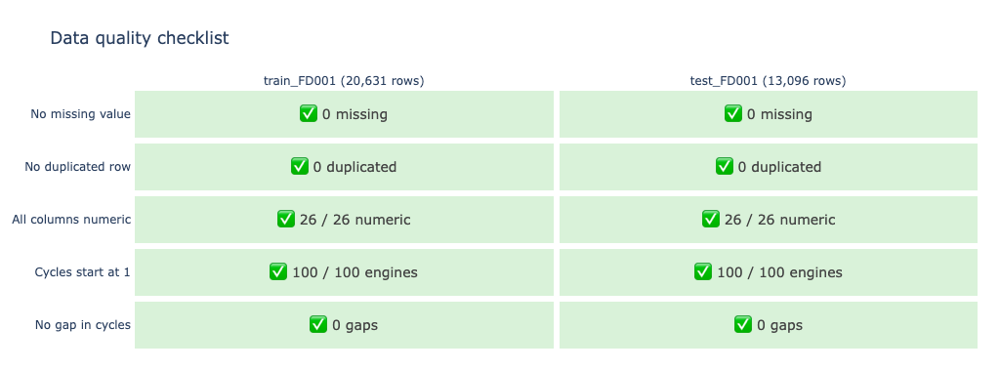

✅ 10 / 10 checks passed: nothing to impute, nothing to encode


In [7]:
# Each check returns (passed?, text to display) for one file
checks = {
    "No missing value":        lambda df: (df.isna().sum().sum() == 0, f"{df.isna().sum().sum()} missing"),
    "No duplicated row":       lambda df: (df.duplicated().sum() == 0, f"{df.duplicated().sum()} duplicated"),
    "All columns numeric":     lambda df: ((df.dtypes == "object").sum() == 0, f"{(df.dtypes != 'object').sum()} / {df.shape[1]} numeric"),
    "Cycles start at 1":       lambda df: ((df.groupby("unit")["cycle"].min() == 1).all(),
                                           f"{(df.groupby('unit')['cycle'].min() == 1).sum()} / {df['unit'].nunique()} engines"),
    "No gap in cycles":        lambda df: ((df.groupby("unit")["cycle"].diff().dropna() == 1).all(),
                                           f"{(df.groupby('unit')['cycle'].diff().dropna() != 1).sum()} gaps"),
}
# The two files to check
datasets = {f"train_FD001 ({len(train):,} rows)": train, f"test_FD001 ({len(test):,} rows)": test}

# Run every check on every file
passed = [[int(check(df)[0]) for df in datasets.values()] for check in checks.values()]
labels = [[("✅ " if check(df)[0] else "❌ ") + check(df)[1] for df in datasets.values()] for check in checks.values()]

# Checklist figure: green cell = passed, red cell = failed
fig = go.Figure(go.Heatmap(
    z=passed, x=list(datasets), y=list(checks), text=labels, texttemplate="%{text}", textfont_size=14,
    zmin=0, zmax=1, colorscale=[[0, "#f7d4d4"], [1, "#d9f2d9"]], showscale=False, xgap=6, ygap=6,
    hovertemplate="%{y}<br>%{x}<br>%{text}<extra></extra>"))
fig.update_yaxes(autorange="reversed", showgrid=False)
fig.update_xaxes(side="top", showgrid=False)
fig.update_layout(template=TEMPLATE, height=380, margin=dict(l=20, r=20, t=90, b=20),
                  title="Data quality checklist")
fig.show()

# Overall verdict
n_passed, n_total = int(np.sum(passed)), int(np.size(passed))
print(f"✅ {n_passed} / {n_total} checks passed: nothing to impute, nothing to encode" if n_passed == n_total
      else f"⚠️ {n_total - n_passed} check(s) failed, see the checklist")

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- ✅ No missing value, no duplicate, every column is numeric: **no imputation and no categorical encoding are needed**. This is expected from simulated data.
- ✅ Every engine has one row per cycle, from cycle 1, without gaps: each engine is a complete time series.

</div>

<a id="sub-2-2"></a>

---

### 📋 2.2 Descriptive statistics

In [8]:
# Mean, standard deviation, min and max of every setting and sensor
train[SETTINGS + SENSORS].describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
setting_1,-0.000,0.002,-0.009,0.009
setting_2,0.000,0.000,-0.001,0.001
setting_3,100.000,0.000,100.000,100.000
s1,518.670,0.000,518.670,518.670
s2,642.681,0.500,641.210,644.530
s3,1590.523,6.131,1571.040,1616.910
s4,1408.934,9.001,1382.250,1441.490
s5,14.620,0.000,14.620,14.620
s6,21.610,0.001,21.600,21.610
s7,553.368,0.885,549.850,556.060


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 👀 Several columns have a standard deviation of 0: they never change (see [section 6](#section-6)).
- 📏 The sensors live on very different scales (about 8 for `s15`, about 9,000 for `s9`), so distance-based models such as k-NN and SVM **will need standardisation**.

</div>

---

<a id="conclusion-2"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 🏁 2.3 Conclusion

🎯 **Goal of the section**: Check that nothing has to be repaired before analysing the data.

✅ **What we found.**
- ✅ **Nothing to repair.** No missing value, no duplicate and only numeric columns, in train and in test: no imputation and no encoding are needed.
- 🔢 **Complete time series.** Every engine has one row per cycle, starting at cycle 1, without gaps.
- 👀 **Constant columns.** Several columns have a standard deviation of 0: they never change.
- 📏 **Different scales.** The sensors go from about 8 (`s15`) to about 9,000 (`s9`), so distance-based models such as k-NN and SVM will need standardisation.

🔗 **Link with the other sections.** Two things noticed here are handled later: the columns that never change ([section 6](#section-6)) and the very different scales of the sensors ([section 8](#section-8)).

<a href="#section-2">⬆️ Back to the start of the section</a>

</div>

<a id="section-3"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 🔁 3. One engine, one life: what the files record

</div>

<div class="part-block" style="background-color: rgba(26, 127, 100, 0.12); border: 2px solid #1a7f64; border-radius: 6px; padding: 8px 16px; margin-top: 14px; display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 8px;"><span style="font-size: 1.15em;">🧭 <b style="color: #1a7f64;">PART 2 OF 4</b> &nbsp;·&nbsp; <b>What do we want to predict?</b></span><span><a href="#section-1" title="Part 1: What data do we have?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">1</a><a href="#section-3" title="Part 2: What do we want to predict?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: #1a7f64; color: white;">2</a><a href="#section-6" title="Part 3: What can predict it?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">3</a><a href="#section-12" title="Part 4: What do we give to the models?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">4</a></span></div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- 🎯 **Goal**: Understand what is recorded for a training engine and for a test engine, and define the Remaining Useful Life (RUL).
- ❓ **Why**: The files contain no label. To build one, we first have to understand what a recording represents and what "remaining life" means.

<a href="#conclusion-3" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">🏁 Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>📋 Plan of the section</b></p>

| Step | What we do |
|---|---|
| [3.1](#sub-3-1) | [Definition and formula of the RUL, for train and for test](#sub-3-1) |
| [3.2](#sub-3-2) | [A training engine and a test engine, side by side](#sub-3-2) |
| [3.3](#conclusion-3) | [Conclusion](#conclusion-3) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

📘 **Context and method**

🔑 This is the key to the whole dataset.

- 🛠️ A **training engine** is recorded from its first flight until the flight where it **fails**. Its last row is the failure.
- 🧪 A **test engine** is recorded from its first flight until an arbitrary point **before** failure. How many cycles it had left is given in `RUL_FD001`.

</div>

<a id="sub-3-1"></a>

---

### ⏳ 3.1 The Remaining Useful Life (RUL)

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

The quantity of interest is the **Remaining Useful Life**: how many more cycles (flights) an engine can do before it fails.

For a **training engine**, it is computed as:

$$\text{RUL}(t) = T_{\text{fail}} - t$$

| Symbol | Meaning | Where it is in the data |
|---|---|---|
| $t$ | The cycle we are looking at: the number of flights the engine has done so far | Column `cycle` of the row |
| $T_{\text{fail}}$ | The cycle at which this engine fails | The **largest** value of `cycle` for this engine in `train_FD001` (its last row) |
| $\text{RUL}(t)$ | The number of cycles left between cycle $t$ and the failure | Not in the file: we compute it |

✏️ **Example.** Training engine 39 has 128 rows, so it fails at cycle $T_{\text{fail}} = 128$. At cycle $t = 90$:

$$\text{RUL}(90) = 128 - 90 = 38 \text{ cycles left}$$

On its last row, $t = 128$ and $\text{RUL}(128) = 128 - 128 = 0$: the engine has failed.

For a **test engine**, the recording stops before the failure, so $T_{\text{fail}}$ is not in the file. Its RUL is rebuilt from the answer key:

$$\text{RUL}(t) = (t_{\text{last}} - t) + \text{RUL}_{\text{file}}$$

| Symbol | Meaning | Where it is in the data |
|---|---|---|
| $t_{\text{last}}$ | The last recorded cycle of this test engine | The largest value of `cycle` for this engine in `test_FD001` |
| $\text{RUL}_{\text{file}}$ | The number of cycles the engine had left at $t_{\text{last}}$ | The line of this engine in `RUL_FD001` |

</div>

<a id="sub-3-2"></a>

---

### 🖼️ 3.2 A training engine and a test engine, side by side

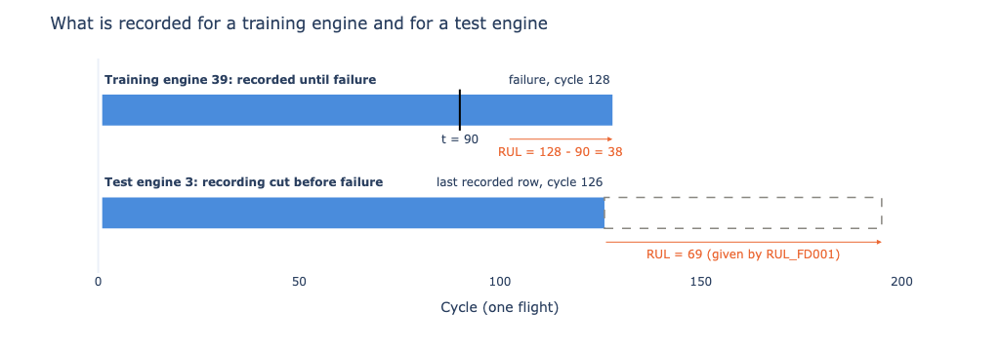

In [9]:
# Helper: draw the life of one engine as a horizontal bar
def add_engine_bar(fig, y, recorded, total, name):
    """Draw one engine life: solid = recorded cycles, dashed = cycles not in the file."""
    fig.add_shape(type="rect", x0=1, x1=recorded, y0=y - 0.18, y1=y + 0.18,
                  fillcolor=BLUE, opacity=0.85, line_width=0)
    if total > recorded:
        fig.add_shape(type="rect", x0=recorded, x1=total, y0=y - 0.18, y1=y + 0.18,
                      line=dict(color=GREY, dash="dash", width=1.5))
    fig.add_annotation(x=1, y=y + 0.36, text=f"<b>{name}</b>", showarrow=False, xanchor="left")

# Engines used as examples, and their key cycles
train_unit, test_unit, t_example = 39, 3, 90
t_fail = train.loc[train["unit"] == train_unit, "cycle"].max()
t_last = test.loc[test["unit"] == test_unit, "cycle"].max()
true_rul = rul_test.loc[rul_test["unit"] == test_unit, "RUL"].iloc[0]

# One bar per engine
fig = go.Figure()
fig.add_scatter(x=[None], y=[None], showlegend=False)      # empty trace so that the axes are drawn
add_engine_bar(fig, 2.2, t_fail, t_fail, f"Training engine {train_unit}: recorded until failure")
add_engine_bar(fig, 1, t_last, t_last + true_rul, f"Test engine {test_unit}: recording cut before failure")

# Training engine: RUL at an example cycle t
fig.add_shape(type="line", x0=t_example, x1=t_example, y0=1.96, y1=2.44, line=dict(color="black", width=2))
fig.add_annotation(x=t_example, y=1.86, text=f"t = {t_example}", showarrow=False)
fig.add_annotation(x=t_fail, y=1.86, ax=t_example + 12, ay=1.86, xref="x", yref="y", axref="x", ayref="y",
                   arrowhead=2, arrowcolor=ORANGE, text="")
fig.add_annotation(x=(t_example + t_fail) / 2 + 6, y=1.72, showarrow=False, font_color=ORANGE,
                   text=f"RUL = {t_fail} - {t_example} = {t_fail - t_example}")
fig.add_annotation(x=t_fail, y=2.56, text=f"failure, cycle {t_fail}", showarrow=False, xanchor="right")

# Test engine: RUL at the last recorded cycle comes from RUL_FD001
fig.add_annotation(x=t_last, y=1.36, text=f"last recorded row, cycle {t_last}", showarrow=False, xanchor="right")
fig.add_annotation(x=t_last + true_rul, y=0.66, ax=t_last, ay=0.66, xref="x", yref="y", axref="x", ayref="y",
                   arrowhead=2, arrowcolor=ORANGE, text="")
fig.add_annotation(x=t_last + true_rul / 2, y=0.52, showarrow=False, font_color=ORANGE,
                   text=f"RUL = {true_rul} (given by RUL_FD001)")

# Axes and title
fig.update_xaxes(title="Cycle (one flight)", range=[-5, max(t_fail, t_last + true_rul) + 10], showgrid=False)
fig.update_yaxes(visible=False, range=[0.3, 2.8])
fig.update_layout(template=TEMPLATE, height=360, margin=dict(t=60),
                  title="What is recorded for a training engine and for a test engine")
fig.show()

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 🛠️ Training engine 39 fails at cycle 128, so at cycle 90 its RUL is $128 - 90 = 38$. We can compute the RUL of **every** training row.
- 🧪 Test engine 3 stops being recorded at cycle 126 and the file says it had 69 cycles left. The RUL of its last row is **given**, and the RUL of its earlier rows can be rebuilt from it.

👉 **Consequence:** we train on all 20,631 training rows. For the final evaluation, the convention of this dataset is one prediction per test engine, at its last recorded row (100 predictions).

</div>

---

<a id="conclusion-3"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 🏁 3.3 Conclusion

🎯 **Goal of the section**: Understand what is recorded for a training engine and for a test engine, and define the Remaining Useful Life (RUL).

✅ **What we found.**
- 🛠️ **Training engine.** Recorded until its failure, so its RUL is known on every row: $\text{RUL}(t) = T_{\text{fail}} - t$.
- 🧪 **Test engine.** Recorded until a point before failure; its RUL is rebuilt from the answer key: $\text{RUL}(t) = (t_{\text{last}} - t) + \text{RUL}_{\text{file}}$.
- 👉 **Consequence.** We train on all 20,631 training rows; for the final evaluation, the convention of this dataset is one prediction per test engine, at its last recorded row (100 predictions).

🔗 **Link with the other sections.** The RUL defined here is the basis of the label built in [section 5](#section-5).

<a href="#section-3">⬆️ Back to the start of the section</a>

</div>

<a id="section-4"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## ⚙️ 4. What do we know about the engines?

</div>

<div class="part-block" style="background-color: rgba(26, 127, 100, 0.12); border: 2px solid #1a7f64; border-radius: 6px; padding: 8px 16px; margin-top: 14px; display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 8px;"><span style="font-size: 1.15em;">🧭 <b style="color: #1a7f64;">PART 2 OF 4</b> &nbsp;·&nbsp; <b>What do we want to predict?</b></span><span><a href="#section-1" title="Part 1: What data do we have?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">1</a><a href="#section-3" title="Part 2: What do we want to predict?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: #1a7f64; color: white;">2</a><a href="#section-6" title="Part 3: What can predict it?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">3</a><a href="#section-12" title="Part 4: What do we give to the models?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">4</a></span></div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- 🎯 **Goal**: Answer three independent questions about the engines: how long they live, whether the test engines resemble the training engines, and how the rows of an engine must be split to validate a model.
- ❓ **Why**: Each answer decides something for the rest of the project: whether the sensors are needed, whether what is learned on the training file applies to the test file, and how a model must be validated.

<a href="#conclusion-4" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">🏁 Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>📋 Plan of the section</b></p>

| Step | What we do |
|---|---|
| [4.1](#sub-4-1) | [How long does an engine live?](#sub-4-1) |
| [4.2](#sub-4-2) | [Are the test engines comparable to the training engines?](#sub-4-2) |
| [4.3](#sub-4-3) | [How must the rows of an engine be split to validate a model?](#sub-4-3) |
| [4.4](#conclusion-4) | [Conclusion](#conclusion-4) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

📘 **Context and method**

This section looks at the engines from three angles. The three questions are independent of each other.

| Angle | Question | What the answer decides |
|---|---|---|
| ⏳ **Lifetime** ([4.1](#sub-4-1)) | How long does an engine live? | Whether the age of an engine is enough to predict its failure, or whether the sensors are needed |
| 🆚 **Train versus test** ([4.2](#sub-4-2)) | Are the test engines comparable to the training engines? | Whether what a model learns on the training file applies to the test file |
| 🧱 **Validation** ([4.3](#sub-4-3)) | How must the rows of an engine be split to validate a model? | How the score of a model is measured before the test file is used |

</div>

<a id="sub-4-1"></a>

---

### ⏳ 4.1 How long does an engine live?

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

🤔 If all engines failed at the same age, the cycle number alone would be enough to predict failure and the sensors would be useless.

We look at the distribution of the **lifetime** of each training engine, i.e. its failure cycle $T_{\text{fail}}$ (the number of flights it did before failing).

</div>

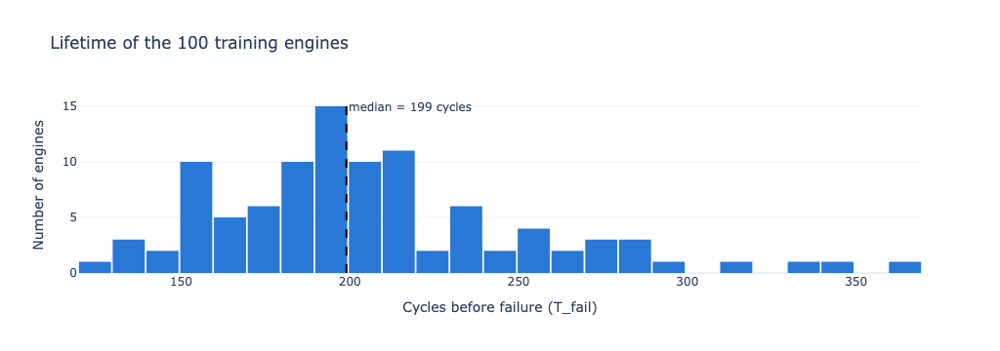

⚡ Shortest life : 128 cycles (engine 39)
🐢 Longest life  : 362 cycles (engine 69)
📊 Mean / median : 206.3 / 199 cycles | std = 46.3
📏 Ratio longest / shortest : 2.8x


In [10]:
# Lifetime of each training engine = its last recorded cycle
life = train.groupby("unit")["cycle"].max().rename("lifetime")

# Histogram of the 100 lifetimes, with the median
fig = px.histogram(life, x="lifetime", nbins=24, color_discrete_sequence=[BLUE], template=TEMPLATE,
                   title="Lifetime of the 100 training engines")
fig.add_vline(x=life.median(), line_dash="dash", line_color="black",
              annotation_text=f"median = {life.median():.0f} cycles")
fig.update_layout(xaxis_title="Cycles before failure (T_fail)", yaxis_title="Number of engines", bargap=0.05)
fig.show()

# Key figures
print(f"⚡ Shortest life : {life.min()} cycles (engine {life.idxmin()})")
print(f"🐢 Longest life  : {life.max()} cycles (engine {life.idxmax()})")
print(f"📊 Mean / median : {life.mean():.1f} / {life.median():.0f} cycles | std = {life.std():.1f}")
print(f"📏 Ratio longest / shortest : {life.max() / life.min():.1f}x")

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 📏 Lifetimes range from 128 to 362 cycles (a factor of 2.8), with a median of 199 and a standard deviation of 46.
- 📊 The distribution is skewed to the right: most engines fail around 150 to 230 cycles and a few last much longer.
- 🤷 An engine at cycle 150 can be at the very end of its life or not even halfway.

👉 **Age alone cannot tell us when an engine will fail; the information has to come from the sensors.**

</div>

<a id="sub-4-2"></a>

---

### 🆚 4.2 Are the test engines comparable to the training engines?

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

⚠️ Both files number their engines from 1 to 100, but they are **different engines**.

We check this, and we check that the two fleets look alike, otherwise what we learn on train would not transfer to test.

</div>

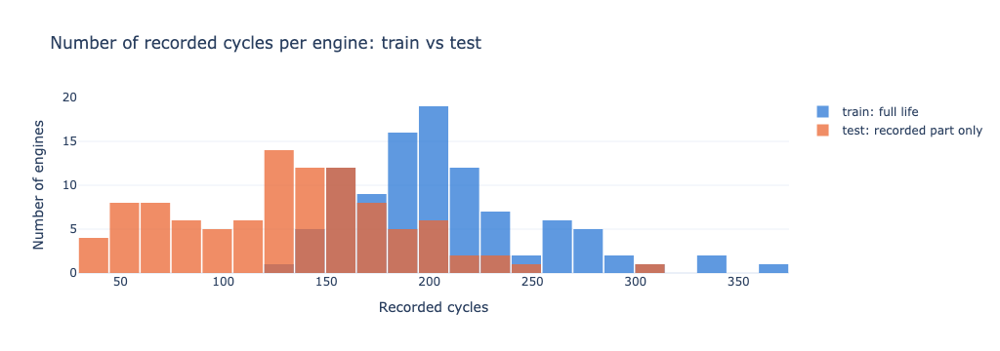

✂️ Recorded cycles per test engine : min 31, median 134, max 303
⏳ True RUL at the cut             : min 7, median 86, max 145
🔁 Reconstructed true lifetime     : median 199 cycles (train median: 199)
🚫 Rows with identical readings in train and test : 0


In [11]:
# Per test engine: recorded cycles, true RUL and rebuilt lifetime
test_len = test.groupby("unit")["cycle"].max().rename("recorded")
test_summary = pd.DataFrame({"recorded": test_len.values, "true_RUL": rul_test["RUL"].values},
                            index=test_len.index)
test_summary["true_lifetime"] = test_summary["recorded"] + test_summary["true_RUL"]

# Recorded cycles per engine: train (full life) vs test (cut before failure)
fig = go.Figure()
fig.add_histogram(x=life, name="train: full life", marker_color=BLUE, opacity=0.75, xbins=dict(size=15))
fig.add_histogram(x=test_summary["recorded"], name="test: recorded part only", marker_color=ORANGE,
                  opacity=0.75, xbins=dict(size=15))
fig.update_layout(template=TEMPLATE, barmode="overlay", bargap=0.05,
                  title="Number of recorded cycles per engine: train vs test",
                  xaxis_title="Recorded cycles", yaxis_title="Number of engines")
fig.show()

# Key figures
print(f"✂️ Recorded cycles per test engine : min {test_summary['recorded'].min()}, "
      f"median {test_summary['recorded'].median():.0f}, max {test_summary['recorded'].max()}")
print(f"⏳ True RUL at the cut             : min {test_summary['true_RUL'].min()}, "
      f"median {test_summary['true_RUL'].median():.0f}, max {test_summary['true_RUL'].max()}")
print(f"🔁 Reconstructed true lifetime     : median {test_summary['true_lifetime'].median():.0f} cycles "
      f"(train median: {life.median():.0f})")
# Check that no row of readings is shared between train and test
shared = train.merge(test, on=SETTINGS + SENSORS)
print(f"🚫 Rows with identical readings in train and test : {len(shared)}")

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- ✂️ Test recordings are shorter (median 134 cycles against 199), which is expected since they are cut before failure. Some stop very early (31 cycles), others very late (7 cycles before failure).
- ✅ If we add the true RUL back, the median lifetime of the test engines is 199 cycles, identical to the training fleet: **the two sets come from the same population**.
- 🚫 No row of sensor readings is shared between the two files: the test engines really are unseen engines.

⚠️ **Same number, different engine.** Engine 1 of the train file and engine 1 of the test file are two different engines.

</div>

<a id="sub-4-3"></a>

---

### 🧱 4.3 How must the rows of an engine be split to validate a model?

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

📘 **Context and method**

- 🧪 **The test file only contains engines the model has never seen.**
- 🪞 **Validation set.** To estimate the score of a model before using the test file, we put part of the training file aside. The model does not learn on these rows; they are only used to measure its score. Cross-validation repeats this several times, with a different part each time.
- ✅ **Rule.** The validation set must put the model in the same situation as the test file. So **all the rows of an engine go on the same side**: all in training, or all in validation.

We compare two ways of putting 20% of the training file aside:

| | How the 20% are chosen | In scikit-learn |
|---|---|---|
| 🎲 **A) Split by row** | 20% of the **rows**, drawn at random | what `train_test_split` does by default |
| 🧱 **B) Split by engine** | 20 **engines** out of 100, with all their rows | `GroupKFold`, with the column `unit` as groups |

</div>

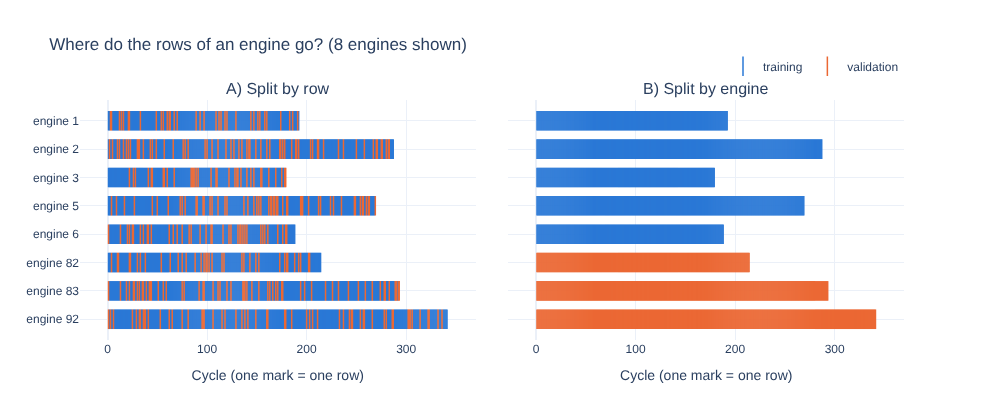

🎲 A) Split by row    : 4,077 validation rows | engines with rows on both sides: 100 / 100 | validation rows whose previous or next flight is in training: 97%
🧱 B) Split by engine : 4,391 validation rows | engines with rows on both sides: 0 / 100 | validation rows whose previous or next flight is in training: 0%


In [ ]:
# Two ways to put 20% of the training file aside as a validation set
rng = np.random.default_rng(0)

# A) Split by row: every row has a 20% chance of going to validation, whatever its engine
val_by_row = pd.Series(rng.random(len(train)) < 0.20, index=train.index)

# B) Split by engine: 20 engines out of 100 go to validation, with all their rows
val_engines = rng.choice(train["unit"].unique(), size=20, replace=False)
val_by_engine = train["unit"].isin(val_engines)

splits = {"A) Split by row": val_by_row, "B) Split by engine": val_by_engine}

# Figure: every row of 8 engines (3 validation engines of split B, 5 others), coloured by its side
shown = sorted(list(val_engines[:3]) + [u for u in train["unit"].unique() if u not in val_engines][:5])
fig = make_subplots(rows=1, cols=2, shared_yaxes=True, subplot_titles=list(splits), horizontal_spacing=0.04)
for col, in_val in enumerate(splits.values(), start=1):
    for side, colour, mask in [("training", BLUE, ~in_val), ("validation", ORANGE, in_val)]:
        rows = train[mask & train["unit"].isin(shown)]
        fig.add_scatter(x=rows["cycle"], y="engine " + rows["unit"].astype(str), mode="markers",
                        marker=dict(color=colour, symbol="line-ns", size=14, line=dict(color=colour, width=1.5)),
                        name=side, showlegend=(col == 1), row=1, col=col)
fig.update_xaxes(title_text="Cycle (one mark = one row)")
fig.update_yaxes(categoryorder="array", categoryarray=[f"engine {u}" for u in shown[::-1]])
fig.update_layout(template=TEMPLATE, height=420, title="Where do the rows of an engine go? (8 engines shown)",
                  legend=dict(orientation="h", yanchor="bottom", y=1.08, xanchor="right", x=1))
fig.show()

# Key figures, on the 100 engines
for name, in_val in splits.items():
    both_sides = len(set(train.loc[in_val, "unit"]) & set(train.loc[~in_val, "unit"]))
    # Is the previous or the next flight of the same engine in the training set?
    previous_in_train = in_val.groupby(train["unit"]).shift(1) == False
    next_in_train = in_val.groupby(train["unit"]).shift(-1) == False
    with_neighbour = (previous_in_train | next_in_train)[in_val].mean()
    print(f"{'🎲' if 'row' in name else '🧱'} {name:<19}: {in_val.sum():,} validation rows | "
          f"engines with rows on both sides: {both_sides} / 100 | "
          f"validation rows whose previous or next flight is in training: {with_neighbour:.0%}")

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 🎲 **A) Split by row.** All 100 engines have rows on both sides. For 97% of the validation rows, the previous or the next flight of the same engine is in the training set, and its RUL differs by only 1 cycle.
- 🧱 **B) Split by engine.** No engine is on both sides. The 20 validation engines are completely unknown to the model, like the 100 test engines.
- ❌ **Why A is wrong.** With A, the validation score answers "can the model fill the gaps of an engine it already knows?". The test file asks another question: "can the model handle a new engine?". Only B asks that question.

👉 **Decision for the modelling stage: split by engine (B).** We did not measure here by how much split A overestimates the score; this can be checked at the modelling stage.

</div>

---

<a id="conclusion-4"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 🏁 4.4 Conclusion

🎯 **Goal of the section**: Answer three independent questions about the engines: how long they live, whether the test engines resemble the training engines, and how the rows of an engine must be split to validate a model.

✅ **What we found.**
- ⏳ **4.1 Age is not enough.** Lifetimes range from 128 to 362 cycles (a factor of 2.8), with a median of 199: an engine at cycle 150 can be at the end of its life or not even halfway.
- 🆚 **4.2 Test engines are comparable.** They are different engines (no row of readings is shared with the training file) from the same population (same median lifetime, 199 cycles).
- ✂️ **Test recordings are shorter.** Median of 134 recorded cycles, since they are cut before failure.
- ⚠️ **Same number, different engine.** Engine 1 of the train file and engine 1 of the test file are two different engines.
- 🧱 **4.3 One engine, one side.** To evaluate a model before the test, all the rows of an engine must be on the same side, training or validation. If the rows are split at random, 100 engines out of 100 have rows on both sides, and the model is evaluated on engines it already knows.

🔗 **Link with the other sections.** The information has to come from the sensors, studied in sections [6](#section-6) to [11](#section-11).

<a href="#section-4">⬆️ Back to the start of the section</a>

</div>

<a id="section-5"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 🎯 5. Building the target

</div>

<div class="part-block" style="background-color: rgba(26, 127, 100, 0.12); border: 2px solid #1a7f64; border-radius: 6px; padding: 8px 16px; margin-top: 14px; display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 8px;"><span style="font-size: 1.15em;">🧭 <b style="color: #1a7f64;">PART 2 OF 4</b> &nbsp;·&nbsp; <b>What do we want to predict?</b></span><span><a href="#section-1" title="Part 1: What data do we have?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">1</a><a href="#section-3" title="Part 2: What do we want to predict?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: #1a7f64; color: white;">2</a><a href="#section-6" title="Part 3: What can predict it?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">3</a><a href="#section-12" title="Part 4: What do we give to the models?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">4</a></span></div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- 🎯 **Goal**: Build the binary label $y$ that the models will have to predict, and choose the warning window $w$.
- ❓ **Why**: A model needs something to predict, and the files do not provide it. Every later comparison between healthy and failing rows depends on it.

<a href="#conclusion-5" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">🏁 Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>📋 Plan of the section</b></p>

| Step | What we do |
|---|---|
| [5.1](#sub-5-1) | [Step 1: compute the RUL of every training row](#sub-5-1) |
| [5.2](#sub-5-2) | [Step 2: turn the RUL into a binary label](#sub-5-2) |
| [5.3](#sub-5-3) | [Apply the two steps in code](#sub-5-3) |
| [5.4](#sub-5-4) | [The label along the life of an engine](#sub-5-4) |
| [5.5](#sub-5-5) | [Balance of the two classes](#sub-5-5) |
| [5.6](#sub-5-6) | [Label of every test row](#sub-5-6) |
| [5.7](#sub-5-7) | [Effect of the window $w$ on the number of $y = 1$ rows](#sub-5-7) |
| [5.8](#sub-5-8) | [Effect of a wider window on the separation of the classes](#sub-5-8) |
| [5.9](#conclusion-5) | [Conclusion](#conclusion-5) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

📘 **Context and method**

The training file has no label, so we build it in two steps.

</div>

<a id="sub-5-1"></a>

---

### 🧮 5.1 Step 1: compute the RUL of every training row

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

Reminder from [section 3](#section-3). For engine number $i$, at cycle $t$:

$$\text{RUL}_i(t) = T_{\text{fail},\,i} - t$$

| Symbol | Meaning | In the code |
|---|---|---|
| $i$ | The engine number, from 1 to 100 | Column `unit` |
| $t$ | The cycle of the row: number of flights done so far by engine $i$ | Column `cycle` |
| $T_{\text{fail},\,i}$ | The failure cycle of engine $i$, i.e. its last recorded cycle | `groupby("unit")["cycle"].transform("max")` |
| $\text{RUL}_i(t)$ | The number of cycles engine $i$ has left at cycle $t$ | New column `RUL` |

- 🔢 The RUL goes down by 1 at each flight.
- 🏁 It is equal to 0 on the last row of the engine (the failure).
- 🧩 $T_{\text{fail},\,i}$ is different for each engine (from 128 to 362 cycles), which is why the maximum is taken **per engine** with `groupby("unit")`.

</div>

<a id="sub-5-2"></a>

---

### 🏷️ 5.2 Step 2: turn the RUL into a binary label

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

The project asks for a **binary classification**, so we compare the RUL to a threshold:

$$y = \begin{cases} 1 & \text{if } \text{RUL} \le w \\ 0 & \text{if } \text{RUL} > w \end{cases}$$

| Symbol | Meaning | In the code |
|---|---|---|
| $y$ | The label of the row, the value the model must predict | New column `y` |
| $w$ | The **warning window**: how many cycles before the failure we want the alarm to start. It is not computed, **we choose it**. | Constant `W = 30` |
| $y = 1$ 🟠 | The failure is imminent: the engine has $w$ cycles or fewer left | |
| $y = 0$ 🔵 | The engine is healthy enough: it has more than $w$ cycles left | |

✏️ **Example with $w = 30$.** Engine 1 fails at cycle $T_{\text{fail}} = 192$.
- At cycle 161: $\text{RUL} = 192 - 161 = 31 > 30$, so $y = 0$.
- At cycle 162: $\text{RUL} = 192 - 162 = 30 \le 30$, so $y = 1$.
- From cycle 162 to cycle 192, all 31 rows have $y = 1$.

</div>

<a id="sub-5-3"></a>

---

### 💻 5.3 Applying the two steps in code

In [12]:
# Step 1: RUL = T_fail - t, where T_fail is the last cycle of each engine
train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]

# Step 2: y = 1 if RUL <= w, else 0
train["y"] = (train["RUL"] <= W).astype(int)

# Preview on engine 1: first rows, rows around the switch of y, last rows
train.loc[train["unit"] == 1, ["unit", "cycle", "RUL", "y"]].iloc[[0, 1, 160, 161, 162, -2, -1]]

,unit,cycle,RUL,y
0,1,1,191,0
1,1,2,190,0
160,1,161,31,0
161,1,162,30,1
162,1,163,29,1
190,1,191,1,1
191,1,192,0,1


<a id="sub-5-4"></a>

---

### 🎨 5.4 The label along the life of an engine

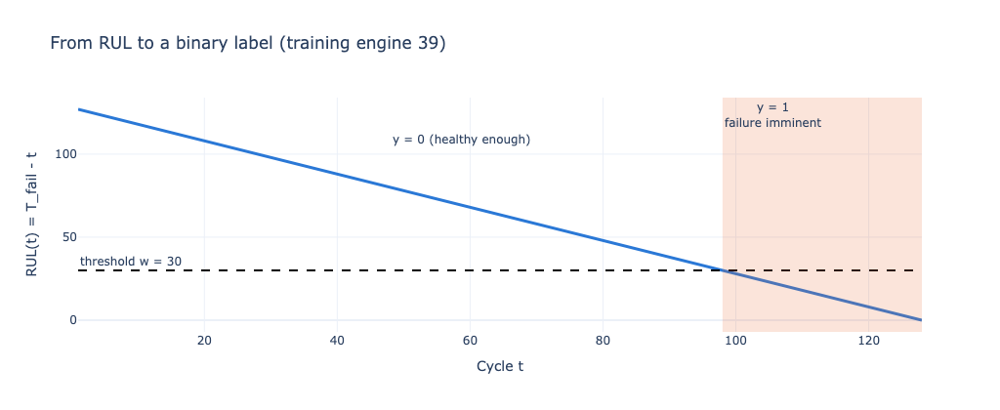

In [13]:
# One training engine as an example
engine = train[train["unit"] == train_unit]

# RUL curve, threshold w, and the zone where y = 1
fig = go.Figure()
fig.add_scatter(x=engine["cycle"], y=engine["RUL"], mode="lines", line=dict(color=BLUE, width=3), name="RUL(t)")
fig.add_hline(y=W, line_dash="dash", line_color="black", annotation_text=f"threshold w = {W}",
              annotation_position="top left")
fig.add_vrect(x0=t_fail - W, x1=t_fail, fillcolor=ORANGE, opacity=0.18, line_width=0,
              annotation_text="y = 1<br>failure imminent", annotation_position="top left")
fig.add_annotation(x=(t_fail - W) * 0.6, y=t_fail * 0.85, text="y = 0 (healthy enough)", showarrow=False)
fig.update_layout(template=TEMPLATE, height=420, showlegend=False,
                  title=f"From RUL to a binary label (training engine {train_unit})",
                  xaxis_title="Cycle t", yaxis_title="RUL(t) = T_fail - t")
fig.show()

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 📉 The RUL decreases by one at each flight and reaches 0 on the failure row.
- 🔀 The label switches from 0 to 1 when the RUL crosses $w$: for engine 1 (192 cycles) this happens at cycle 162, where RUL = 30.

⚠️ **Warning (target leakage).** `RUL` is only a helper column used to build `y`. It must **never** be given to the model as a feature:
- 🎭 since $y$ is defined from it, the model would get a perfect score;
- 🚫 it would be unusable in practice, because the RUL of an engine in service is unknown.

</div>

<a id="sub-5-5"></a>

---

### ⚖️ 5.5 Are the two classes balanced?

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

Class balance decides which metrics are meaningful. We look at it:
- 🛠️ in the training rows
- 🧪 in the 100 test engines (their last recorded row, labelled with the true RUL)

</div>

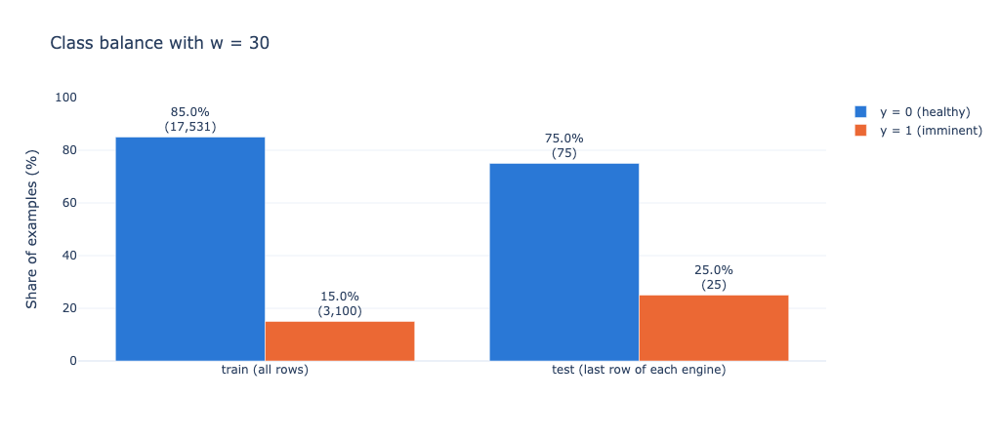

⚖️ Imbalance ratio in train: 5.7 healthy rows for 1 imminent row
⚠️ A model that always answers 'healthy' would reach 85.0% accuracy on train.


In [14]:
# Test engines, last recorded row: the RUL is given by RUL_FD001
test_summary["y"] = (test_summary["true_RUL"] <= W).astype(int)

# Number of rows in each class, for train and for test
balance = pd.DataFrame({
    "train (all rows)": train["y"].value_counts().sort_index(),
    "test (last row of each engine)": test_summary["y"].value_counts().sort_index(),
})
balance.index = ["y = 0 (healthy)", "y = 1 (imminent)"]
share = (balance / balance.sum() * 100).round(1)

# Bar chart of the class shares
fig = go.Figure()
for label, color in zip(share.index, [BLUE, ORANGE]):
    fig.add_bar(x=share.columns, y=share.loc[label], name=label, marker_color=color,
                text=[f"{p}%<br>({n:,})" for p, n in zip(share.loc[label], balance.loc[label])],
                textposition="outside")
fig.update_layout(template=TEMPLATE, barmode="group", height=450, yaxis_range=[0, 100],
                  title=f"Class balance with w = {W}", yaxis_title="Share of examples (%)")
fig.show()

# Key figures
print(f"⚖️ Imbalance ratio in train: {balance.iloc[0, 0] / balance.iloc[1, 0]:.1f} healthy rows for 1 imminent row")
print(f"⚠️ A model that always answers 'healthy' would reach {share.iloc[0, 0]}% accuracy on train.")

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 🟠 **15% of training rows are $y = 1$** (imminent failure): 3,100 out of 20,631. Each engine contributes its last 31 rows (RUL 30 down to 0), and $31 \times 100 = 3{,}100$.
- ⚖️ **The classes are imbalanced**: 5.7 healthy rows for 1 imminent-failure row.
- 🎭 **Accuracy is misleading**: always answering "healthy" gives 85% accuracy and detects no failure.

</div>

<a id="sub-5-6"></a>

---

### 🧪 5.6 Rebuilding the label of every test row

In [15]:
# RUL of every test row, rebuilt from the answer key: RUL(t) = (t_last - t) + RUL_file
last_cycle = test.groupby("unit")["cycle"].transform("max")
test["RUL"] = (last_cycle - test["cycle"]) + test["unit"].map(rul_test.set_index("unit")["RUL"])
test["y"] = (test["RUL"] <= W).astype(int)

# Balance of the test set: all rows, then last row of each engine
print(f"🧪 All test rows       : {len(test):,} rows, {test['y'].sum()} with y = 1 ({test['y'].mean() * 100:.1f}%)")
print(f"🎯 Last row per engine : {len(test_summary)} rows, {test_summary['y'].sum()} with y = 1 "
      f"({test_summary['y'].mean() * 100:.1f}%)")

🧪 All test rows       : 13,096 rows, 332 with y = 1 (2.5%)
🎯 Last row per engine : 100 rows, 25 with y = 1 (25.0%)


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 🧪 **The test balance differs**: 25% of engines have $y = 1$ on their last row, but only 2.5% of all 13,096 test rows do. Expect a gap between cross-validation and test scores.

</div>

<a id="sub-5-7"></a>

---

### 🎚️ 5.7 Effect of the window w

In [16]:
# Share of y = 1 for several values of the window w
w_grid = [10, 20, 30, 40, 50]
pd.DataFrame({
    "w": w_grid,
    "train rows with y = 1, imminent failure (%)": [round((train["RUL"] <= w).mean() * 100, 1) for w in w_grid],
    "test engines with y = 1, imminent failure (%)": [round((test_summary["true_RUL"] <= w).mean() * 100, 1) for w in w_grid],
}).set_index("w")

,"train rows with y = 1, imminent failure (%)","test engines with y = 1, imminent failure (%)"
w,,
10,5.3,7.0
20,10.2,16.0
30,15.0,25.0
40,19.9,28.0
50,24.7,33.0


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 🎚️ **Choice of $w$**: a smaller window makes $y = 1$ rarer (5% at $w = 10$), a larger one blurs the two classes. $w = 30$ is the compromise.

👉 **We will judge models on recall, precision, F1 and AUC.**

🚨 The costly error is the **false negative**: a missed failure.

</div>

<a id="sub-5-8"></a>

---

### 🔭 5.8 What a wider window does to the classes

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

The table above shows the effect of $w$ on the **number** of $y = 1$ rows. Here we look at its effect on **how different** the $y = 1$ rows are from the healthy ones, on sensor `s11`.

- 🔵 The blue curve is the average of `s11` at each number of cycles left.
- 🟠 The orange zone is the class $y = 1$ with our window, $w = 30$.
- 🟡 The yellow zone is what a wider window, $w = 75$, would add to that class.

</div>

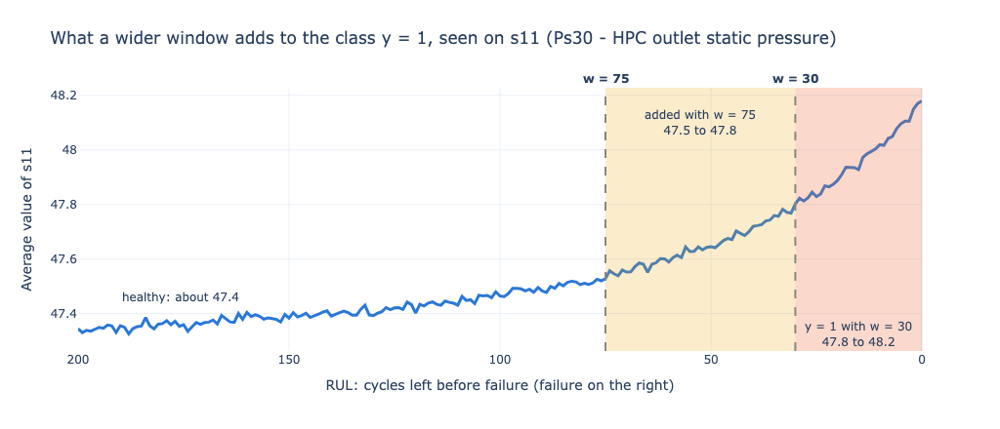

Separation of the two classes on s11, depending on the window:
   w = 10 | average when y = 1: 48.09 | when y = 0: 47.51 | gap = 2.50 standard deviations
   w = 20 | average when y = 1: 48.02 | when y = 0: 47.49 | gap = 2.53 standard deviations
👉 w = 30 | average when y = 1: 47.96 | when y = 0: 47.47 | gap = 2.50 standard deviations
   w = 40 | average when y = 1: 47.91 | when y = 0: 47.45 | gap = 2.39 standard deviations
   w = 50 | average when y = 1: 47.86 | when y = 0: 47.43 | gap = 2.24 standard deviations
   w = 75 | average when y = 1: 47.77 | when y = 0: 47.41 | gap = 1.85 standard deviations


In [17]:
s = "s11"                      # example sensor
W_WIDE = 75                    # a wider window, for comparison with our w
last = train[train["RUL"] <= 200]
avg = last.groupby("RUL")[s].mean()                     # average reading at each number of cycles left
healthy = train.loc[train["RUL"] > 100, s].mean()       # typical value far from failure

# Curve of the average, with the zone covered by each window
fig = go.Figure()
fig.add_vrect(x0=W_WIDE, x1=W, fillcolor="#eda100", opacity=0.20, line_width=0)
fig.add_vrect(x0=W, x1=0, fillcolor=ORANGE, opacity=0.25, line_width=0)
fig.add_scatter(x=avg.index, y=avg, mode="lines", line=dict(color=BLUE, width=3), showlegend=False)
fig.add_vline(x=W, line_dash="dash", line_color=GREY)
fig.add_vline(x=W_WIDE, line_dash="dash", line_color=GREY)
y_top = avg.max()
# Labels of the two windows and of the zones
fig.add_annotation(x=W, y=1, yref="paper", yanchor="bottom", showarrow=False, text=f"<b>w = {W}</b>")
fig.add_annotation(x=W_WIDE, y=1, yref="paper", yanchor="bottom", showarrow=False, text=f"<b>w = {W_WIDE}</b>")
fig.add_annotation(x=W / 2, y=avg.min(), showarrow=False, align="center",
                   text=f"y = 1 with w = {W}<br>{avg[W]:.1f} to {avg[0]:.1f}")
fig.add_annotation(x=(W + W_WIDE) / 2, y=y_top, yshift=-22, showarrow=False, align="center",
                   text=f"added with w = {W_WIDE}<br>{avg[W_WIDE]:.1f} to {avg[W]:.1f}")
fig.add_annotation(x=190, y=healthy, yshift=22, showarrow=False, xanchor="left", text=f"healthy: about {healthy:.1f}")
# Axes and title
fig.update_xaxes(autorange="reversed", title="RUL: cycles left before failure (failure on the right)")
fig.update_yaxes(title=f"Average value of {s}")
fig.update_layout(template=TEMPLATE, height=440, margin=dict(t=90),
                  title=f"What a wider window adds to the class y = 1, seen on {s} ({SENSOR_NAMES[s]})")
fig.show()

# Gap between the two classes, in standard deviations, for each window
print(f"Separation of the two classes on {s}, depending on the window:")
for w in [10, 20, 30, 40, 50, 75]:
    y1, y0 = train.loc[train["RUL"] <= w, s], train.loc[train["RUL"] > w, s]
    pooled = np.sqrt(((len(y1) - 1) * y1.var() + (len(y0) - 1) * y0.var()) / (len(train) - 2))
    marker = "👉" if w == W else "  "
    print(f"{marker} w = {w:>2} | average when y = 1: {y1.mean():.2f} | when y = 0: {y0.mean():.2f} "
          f"| gap = {(y1.mean() - y0.mean()) / pooled:.2f} standard deviations")

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 🔵 Far from failure, `s11` reads about 47.4.
- 🟠 **With $w = 30$**, the class $y = 1$ only contains readings from 47.8 to 48.2: clearly above the healthy value, so the two classes are easy to tell apart.
- 🟡 **With $w = 75$**, the class $y = 1$ would also take in readings from 47.5 to 47.8: close to the healthy value, yet labelled "imminent failure". The two classes would overlap more.
- 📏 **The numbers confirm it.** The gap between the two class averages is the same from $w = 10$ to $w = 30$ (about 2.5 standard deviations), then decreases: 2.39 at $w = 40$, 2.24 at $w = 50$, 1.85 at $w = 75$.

✅ **$w = 30$ is the largest window that keeps the two classes fully separated on this sensor**, while giving three times more $y = 1$ rows than $w = 10$ (15% against 5%).

</div>

---

<a id="conclusion-5"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 🏁 5.9 Conclusion

🎯 **Goal of the section**: Build the binary label $y$ that the models will have to predict, and choose the warning window $w$.

✅ **What we found.**
- 🏷️ **The label.** We compute $\text{RUL} = T_{\text{fail}} - t$ for every training row, then $y = 1$ if $\text{RUL} \le w$ and $y = 0$ otherwise.
- 🎚️ **The choice of $w$: we keep $w = 30$ cycles.** A smaller window leaves too few $y = 1$ rows (5% of the training rows at $w = 10$, against 15% at $w = 30$). A larger window adds rows that are still close to healthy: on `s11`, the gap between the two classes is the same from $w = 10$ to $w = 30$ (about 2.5 standard deviations), then decreases (2.24 at $w = 50$, 1.85 at $w = 75$). $w = 30$ is the largest window that keeps the two classes fully separated on this sensor.
- ⚖️ **The classes are imbalanced.** 3,100 training rows out of 20,631 are $y = 1$ (15%), i.e. 5.7 healthy rows for 1 imminent-failure row.
- 🎭 **Consequence for the metrics.** Always answering "healthy" gives 85% accuracy and detects no failure, so the models will be judged on recall, precision, F1 and AUC; the costly error is the false negative (a missed failure).
- 🧪 **In the test set.** 25% of the engines have $y = 1$ on their last recorded row, and 2.5% of all 13,096 test rows.
- 🚫 **Target leakage.** `RUL` is only used to build $y$: it must never be given to the model as a feature.

🔗 **Link with the other sections.** This label is used from [section 8](#section-8) onwards to compare the two classes, and it is what the models of the next stage will have to predict.

<a href="#section-5">⬆️ Back to the start of the section</a>

</div>

<a id="section-6"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 🔍 6. Which columns carry information?

</div>

<div class="part-block" style="background-color: rgba(26, 127, 100, 0.12); border: 2px solid #1a7f64; border-radius: 6px; padding: 8px 16px; margin-top: 14px; display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 8px;"><span style="font-size: 1.15em;">🧭 <b style="color: #1a7f64;">PART 3 OF 4</b> &nbsp;·&nbsp; <b>What can predict it?</b></span><span><a href="#section-1" title="Part 1: What data do we have?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">1</a><a href="#section-3" title="Part 2: What do we want to predict?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">2</a><a href="#section-6" title="Part 3: What can predict it?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: #1a7f64; color: white;">3</a><a href="#section-12" title="Part 4: What do we give to the models?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">4</a></span></div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- 🎯 **Goal**: Find which of the 24 setting and sensor columns can help the model.
- ❓ **Why**: We have 24 candidate columns. Those that never change cannot help, so we remove them before analysing the rest.

<a href="#conclusion-6" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">🏁 Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>📋 Plan of the section</b></p>

| Step | What we do |
|---|---|
| [6.1](#sub-6-1) | [An example: a sensor that never changes and a sensor that drifts](#sub-6-1) |
| [6.2](#sub-6-2) | [The same check on the 24 columns](#sub-6-2) |
| [6.3](#sub-6-3) | [The two settings that still vary](#sub-6-3) |
| [6.4](#conclusion-6) | [Conclusion](#conclusion-6) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

📘 **Context and method**

🎯 **The question.** A model can only learn from a column whose value is different when the engine is healthy and when it is about to fail. So we ask of each column: **does it ever change?**

<hr style="border: none; border-top: 1px solid rgba(31, 119, 180, 0.30); margin: 10px 0;">

🧱 **What we expect.** All FD001 engines fly in the same condition (sea level), so some measurements, like the temperature of the air entering the engine, should be identical on every flight.

<hr style="border: none; border-top: 1px solid rgba(31, 119, 180, 0.30); margin: 10px 0;">

📊 **How we check.** For each column, we look at its most common value and count the share of rows that show it:
- 100% means the column shows the same number on every row: it is constant.
- A low percentage means the column takes many different values: it varies.

<hr style="border: none; border-top: 1px solid rgba(31, 119, 180, 0.30); margin: 10px 0;">

🗑️ **The rule.** We drop a column when a single value covers at least 95% of its rows.

</div>

<a id="sub-6-1"></a>

---

### 🔎 6.1 An example: two sensors of the same engine

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

Before checking all the columns, we look at two sensors of one engine over its whole life, from its first flight to its failure.

</div>

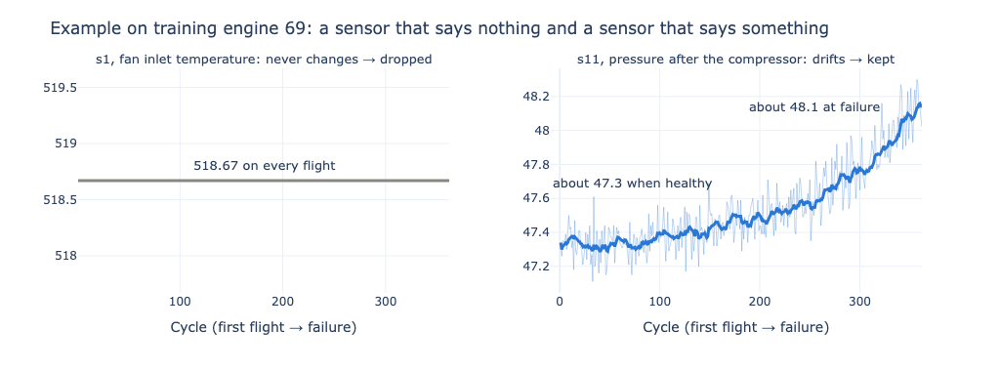

🧱 s1  : 518.67 on the first flight, 518.67 on the last one. Same value: no information.
📈 s11 : about 47.35 at the start of life, 48.14 at failure. It moves with the health of the engine.


In [19]:
example_unit = 69                                   # the engine with the longest life
one = train[train["unit"] == example_unit]
smooth = one["s11"].rolling(10, min_periods=1).mean()          # average of the last 10 flights, to see the trend
start, end = smooth.iloc[:20].mean(), smooth.iloc[-1]

# Two panels side by side
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.12, subplot_titles=[
    "s1, fan inlet temperature: never changes → dropped",
    "s11, pressure after the compressor: drifts → kept"])

# Left: a constant sensor
fig.add_scatter(x=one["cycle"], y=one["s1"], mode="lines", line=dict(color=GREY, width=3),
                showlegend=False, row=1, col=1)
fig.add_annotation(x=one["cycle"].mean(), y=one["s1"].iloc[0], yshift=16, showarrow=False, row=1, col=1,
                   text=f"{one['s1'].iloc[0]:.2f} on every flight")

# Right: an informative sensor (raw readings in light blue, trend in blue)
fig.add_scatter(x=one["cycle"], y=one["s11"], mode="lines", line=dict(color=BLUE, width=1), opacity=0.3,
                showlegend=False, row=1, col=2)
fig.add_scatter(x=one["cycle"], y=smooth, mode="lines", line=dict(color=BLUE, width=3),
                showlegend=False, row=1, col=2)
fig.add_annotation(x=one["cycle"].max() * 0.2, y=start, yshift=60, showarrow=False, row=1, col=2,
                   text=f"about {start:.1f} when healthy")
fig.add_annotation(x=one["cycle"].max() - 40, y=end, xanchor="right", showarrow=False, row=1, col=2,
                   text=f"about {end:.1f} at failure")

# Axes and title
fig.update_yaxes(range=[one["s1"].iloc[0] - 1, one["s1"].iloc[0] + 1], row=1, col=1)
fig.update_xaxes(title_text="Cycle (first flight → failure)")
fig.update_annotations(font_size=13)
fig.update_layout(template=TEMPLATE, height=380, margin=dict(t=70),
                  title=f"Example on training engine {example_unit}: a sensor that says nothing and a sensor that says something")
fig.show()

# Key figures
print(f"🧱 s1  : {one['s1'].min():.2f} on the first flight, {one['s1'].max():.2f} on the last one. Same value: no information.")
print(f"📈 s11 : about {start:.2f} at the start of life, {end:.2f} at failure. It moves with the health of the engine.")

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 🧱 `s1` (T2, fan inlet temperature) shows 518.67 on every flight, whether the engine is healthy or about to fail. It cannot help the model: **dropped**.
- 📈 `s11` (Ps30, HPC outlet static pressure) stays around 47.3 while the engine is healthy, then climbs to about 48.1 as the failure approaches. It carries information: **kept**.

👉 The next step applies the same check to all 24 columns at once.

</div>

<a id="sub-6-2"></a>

---

### 🧱 6.2 Checking the 24 columns

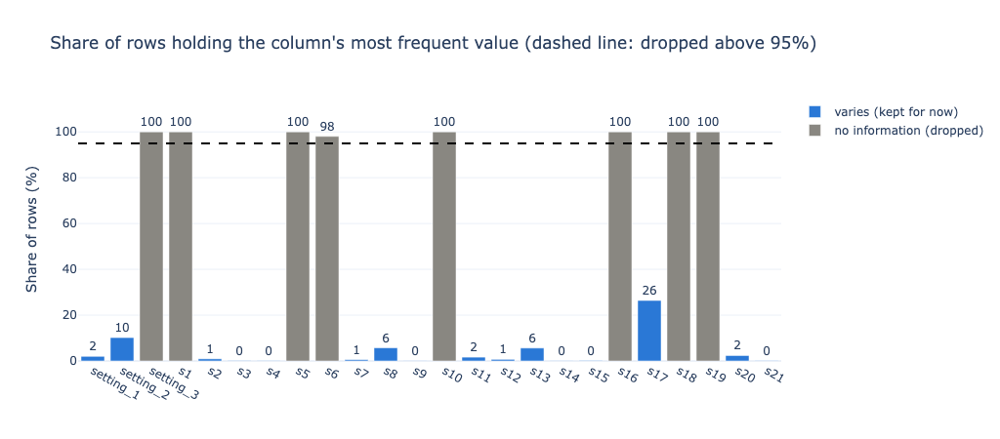

🗑️ Dropped (8): ['setting_3', 's1', 's5', 's6', 's10', 's16', 's18', 's19']
✅ Sensors kept (14): ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


In [17]:
# Columns to check, and the rule used to drop a column
cols = SETTINGS + SENSORS
TOP_SHARE = "rows holding the most frequent value (%)"
DROP_ABOVE = 95        # a column is dropped when one single value covers at least 95% of the rows

# For each column: standard deviation and share of rows holding its most frequent value
info = pd.DataFrame({
    "std": train[cols].std().round(4),
    TOP_SHARE: [train[c].value_counts(normalize=True).iloc[0] * 100 for c in cols],
}, index=cols)
info["status"] = np.where(info[TOP_SHARE] >= DROP_ABOVE, "no information (dropped)", "varies (kept for now)")

# Bar chart, with the drop threshold as a dashed line
fig = px.bar(info.reset_index(names="column"), x="column", y=TOP_SHARE, color="status",
             color_discrete_map={"no information (dropped)": GREY, "varies (kept for now)": BLUE},
             category_orders={"column": cols}, template=TEMPLATE,
             title=f"Share of rows holding the column's most frequent value (dashed line: dropped above {DROP_ABOVE}%)")
fig.update_traces(texttemplate="%{y:.0f}", textposition="outside")
fig.add_hline(y=DROP_ABOVE, line_dash="dash", line_color="black")       # drop threshold
fig.update_layout(xaxis_title="", yaxis_title="Share of rows (%)", yaxis_range=[0, 115], legend_title="", height=450,
                  uniformtext_minsize=11, uniformtext_mode="show")
fig.show()

# Columns dropped, and sensors kept for the rest of the notebook
constant_cols = info.index[info[TOP_SHARE] >= DROP_ABOVE].tolist()
useful_sensors = [s for s in SENSORS if s not in constant_cols]
print(f"🗑️ Dropped ({len(constant_cols)}): {constant_cols}")
print(f"✅ Sensors kept ({len(useful_sensors)}): {useful_sensors}")

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 🗑️ Seven columns are strictly constant (standard deviation of 0, the same value on 100% of the rows): `setting_3`, `s1`, `s5`, `s10`, `s16`, `s18`, `s19`.
- 🗑️ `s6` is constant in practice: it is equal to 21.61 on 98% of the rows and to 21.60 on the other 2%, a change of one unit on its last recorded digit.
- ✅ For every other column, the most frequent value covers at most 26% of the rows (`s17`), so they do vary. **We drop the 8 columns above.**
- 🌍 They are constant because FD001 has a single flight condition: inlet temperature and pressure, for example, never change at sea level.

</div>

<a id="sub-6-3"></a>

---

### 🎛️ 6.3 The two settings that still vary

In [16]:
# Statistics of the settings, and their link with the RUL
print("🎛️ Operational settings:")
print(train[SETTINGS].describe().T[["mean", "std", "min", "max"]])
print("\n🔗 Correlation of the settings with RUL:")
print(train[SETTINGS[:2]].corrwith(train["RUL"]).round(4))

🎛️ Operational settings:
                 mean       std       min       max
setting_1   -0.000009  0.002187   -0.0087    0.0087
setting_2    0.000002  0.000293   -0.0006    0.0006
setting_3  100.000000  0.000000  100.0000  100.0000

🔗 Correlation of the settings with RUL:
setting_1   -0.0032
setting_2   -0.0019
dtype: float64


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 🎛️ `setting_1` and `setting_2` do vary, but only as tiny fluctuations around one operating point, and their correlation with the RUL is about 0 (-0.003 and -0.002). They are noise for our problem, so we do not use them as features.

✅ **14 sensors remain** for the rest of the analysis.

</div>

---

<a id="conclusion-6"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 🏁 6.4 Conclusion

🎯 **Goal of the section**: Find which of the 24 setting and sensor columns can help the model.

✅ **What we found.**
- 🗑️ **8 columns are dropped.** Seven never change (`setting_3`, `s1`, `s5`, `s10`, `s16`, `s18`, `s19`) and `s6` shows the same value on 98% of the rows.
- 🌍 **Why.** FD001 has a single flight condition (sea level), so these measurements are identical on every flight.
- 🎛️ **2 settings are set aside.** `setting_1` and `setting_2` vary slightly, but their correlation with the RUL is about 0: they are noise for our problem.
- ✅ **14 sensors remain**: `s2`, `s3`, `s4`, `s7`, `s8`, `s9`, `s11`, `s12`, `s13`, `s14`, `s15`, `s17`, `s20`, `s21`.

🔗 **Link with the other sections.** All the following sections work on these 14 sensors.

<a href="#section-6">⬆️ Back to the start of the section</a>

</div>

<a id="section-7"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 📉 7. What does degradation look like?

</div>

<div class="part-block" style="background-color: rgba(26, 127, 100, 0.12); border: 2px solid #1a7f64; border-radius: 6px; padding: 8px 16px; margin-top: 14px; display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 8px;"><span style="font-size: 1.15em;">🧭 <b style="color: #1a7f64;">PART 3 OF 4</b> &nbsp;·&nbsp; <b>What can predict it?</b></span><span><a href="#section-1" title="Part 1: What data do we have?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">1</a><a href="#section-3" title="Part 2: What do we want to predict?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">2</a><a href="#section-6" title="Part 3: What can predict it?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: #1a7f64; color: white;">3</a><a href="#section-12" title="Part 4: What do we give to the models?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">4</a></span></div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- 🎯 **Goal**: See how the 14 sensors evolve as an engine approaches its failure.
- ❓ **Why**: Before measuring anything, we look: does an approaching failure leave a visible trace in the sensors? If it does not, no model can predict it.

<a href="#conclusion-7" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">🏁 Go to the conclusion of this section</a>

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

📘 **Context and method**

🧭 Engines have different lifetimes, so plotting sensors against the cycle number would mix engines at different stages of life. Instead we align every engine on its **failure**: the x-axis is the RUL, read from left (200 cycles before failure) to right (failure).

How to read the figure:
- 🔵 blue line: average over all engines
- ⚪ grey lines: three individual engines (a short, a median and a long life)
- 🟠 orange dashed line: our threshold $w$

</div>

<a id="sub-7-1"></a>

---

### 📈 7.1 The 14 sensors over the last 200 cycles

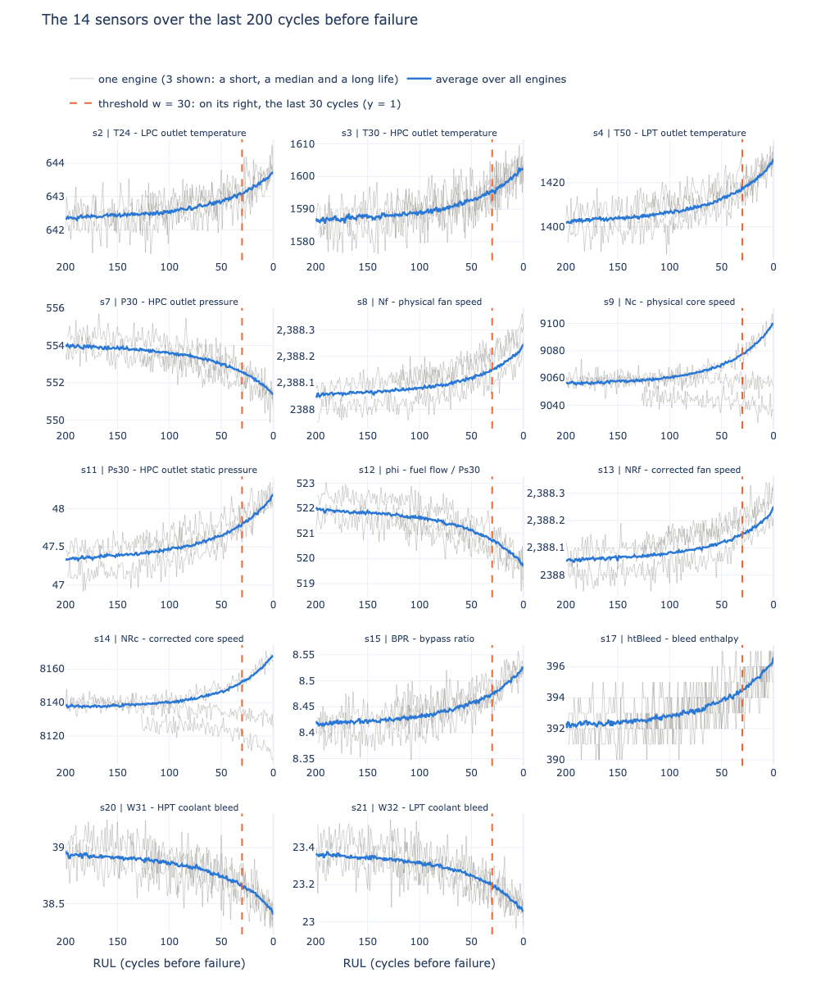

In [21]:
# Average of each sensor at each number of cycles left, plus three example engines
HORIZON = 200      # we look at the last 200 cycles of each engine
mean_by_rul = train[train["RUL"] <= HORIZON].groupby("RUL")[useful_sensors].mean()
sample_units = [39, 79, 69]          # a short, a median and a long life

# One small plot per sensor
fig = make_subplots(rows=5, cols=3, subplot_titles=[f"{s} | {SENSOR_NAMES[s]}" for s in useful_sensors],
                    vertical_spacing=0.06, horizontal_spacing=0.06)
for i, s in enumerate(useful_sensors):
    r, c = i // 3 + 1, i % 3 + 1
    first = (i == 0)                 # the legend entries are declared once, on the first plot
    # Three individual engines, in grey
    for u in sample_units:
        one = train[(train["unit"] == u) & (train["RUL"] <= HORIZON)]
        fig.add_scatter(x=one["RUL"], y=one[s], mode="lines", line=dict(color=GREY, width=0.7), opacity=0.5,
                        name="one engine (3 shown: a short, a median and a long life)", legendgroup="engine",
                        showlegend=(first and u == sample_units[0]), row=r, col=c)
    # Fleet average in blue, and the threshold w
    fig.add_scatter(x=mean_by_rul.index, y=mean_by_rul[s], mode="lines", line=dict(color=BLUE, width=2.5),
                    name="average over all engines", legendgroup="average", showlegend=first, row=r, col=c)
    fig.add_vline(x=W, line_dash="dash", line_color=ORANGE, row=r, col=c)
# Legend entry for the threshold (an empty trace: the dashed lines themselves are drawn by add_vline)
fig.add_scatter(x=[None], y=[None], mode="lines", line=dict(color=ORANGE, dash="dash"),
                name=f"threshold w = {W}: on its right, the last {W} cycles (y = 1)", row=1, col=1)
# Failure on the right: reverse the x-axis
fig.update_xaxes(autorange="reversed")
fig.update_xaxes(title_text="RUL (cycles before failure)", row=5)
fig.update_annotations(font_size=11)
fig.update_layout(template=TEMPLATE, height=1220, margin=dict(t=170),
                  title=dict(text="The 14 sensors over the last 200 cycles before failure", y=0.985, yanchor="top"),
                  legend=dict(orientation="h", yanchor="bottom", y=1.03, xanchor="left", x=0, font_size=13))
fig.show()

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.** ⭐ This is the central figure of the exploration.

👁️ **The degradation is visible.** Once aligned on failure, the sensors follow a common pattern: almost flat far from failure, then a drift that accelerates. This matches the exponential fault growth imposed in the simulation.

📈 **Sensors going up as the failure approaches:**

| Column | Sensor |
|---|---|
| `s2` | T24, LPC outlet temperature |
| `s3` | T30, HPC outlet temperature |
| `s4` | T50, LPT outlet temperature |
| `s8` | Nf, physical fan speed |
| `s11` | Ps30, HPC outlet static pressure |
| `s13` | NRf, corrected fan speed |
| `s15` | BPR, bypass ratio |
| `s17` | htBleed, bleed enthalpy |

📉 **Sensors going down as the failure approaches:**

| Column | Sensor |
|---|---|
| `s7` | P30, HPC outlet pressure |
| `s12` | phi, fuel flow / Ps30 |
| `s20` | W31, HPT coolant bleed |
| `s21` | W32, LPT coolant bleed |

⚠️ **Sensors that behave differently:**

| Column | Sensor |
|---|---|
| `s9` | Nc, physical core speed |
| `s14` | NRc, corrected core speed |

For these two, the fleet average rises, but the three sample engines stay flat or even decrease. They do not respond the same way in every engine, so they will be less reliable.

- 🔧 The two families are physically coherent with a compressor losing efficiency: lower pressure at its outlet, and a hotter engine to deliver the same thrust.
- ✅ **Most of the drift happens before the threshold**, so at $w = 30$ the engine is already clearly away from its healthy state, which is favourable for classification.
- 〰️ **Individual engines are noisy.** The grey curves fluctuate a lot around the average: a single row is an imprecise picture of the engine's state.

</div>

---

<a id="conclusion-7"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 🏁 7.2 Conclusion

🎯 **Goal of the section**: See how the 14 sensors evolve as an engine approaches its failure.

✅ **What we found.**
- 👁️ **The degradation is visible.** Aligned on the failure, the sensors are almost flat far from it, then drift faster and faster.
- 📈 **8 sensors rise**: `s2`, `s3`, `s4`, `s8`, `s11`, `s13`, `s15`, `s17`.
- 📉 **4 sensors fall**: `s7`, `s12`, `s20`, `s21`.
- ⚠️ **2 sensors are unreliable**: `s9` and `s14` do not behave the same way in every engine.
- ✅ **Most of the drift happens before the threshold $w = 30$**, which is favourable for classification.
- 〰️ **Individual engines are noisy**: a single row is an imprecise picture of the engine's state.

🔗 **Link with the other sections.** [Section 8](#section-8) checks whether this drift is enough to separate the two classes of [section 5](#section-5).

<a href="#section-7">⬆️ Back to the start of the section</a>

</div>

<a id="section-8"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 🩺 8. Do the two classes look different?

</div>

<div class="part-block" style="background-color: rgba(26, 127, 100, 0.12); border: 2px solid #1a7f64; border-radius: 6px; padding: 8px 16px; margin-top: 14px; display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 8px;"><span style="font-size: 1.15em;">🧭 <b style="color: #1a7f64;">PART 3 OF 4</b> &nbsp;·&nbsp; <b>What can predict it?</b></span><span><a href="#section-1" title="Part 1: What data do we have?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">1</a><a href="#section-3" title="Part 2: What do we want to predict?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">2</a><a href="#section-6" title="Part 3: What can predict it?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: #1a7f64; color: white;">3</a><a href="#section-12" title="Part 4: What do we give to the models?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">4</a></span></div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- 🎯 **Goal**: Check whether the sensor values are different for healthy rows ($y = 0$) and for imminent-failure rows ($y = 1$).
- ❓ **Why**: A drift on average is not enough: the model has to separate the two classes row by row. We measure how far apart they are.

<a href="#conclusion-8" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">🏁 Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>📋 Plan of the section</b></p>

| Step | What we do |
|---|---|
| [8.1](#sub-8-1) | [Boxplots of the two classes, for the 14 sensors](#sub-8-1) |
| [8.2](#sub-8-2) | [Distributions of the 4 sensors that separate best](#sub-8-2) |
| [8.3](#sub-8-3) | [Zoom on the two weak sensors, `s9` and `s14`](#sub-8-3) |
| [8.4](#sub-8-4) | [Class separation in original sensor space](#sub-8-4) |
| [8.5](#conclusion-8) | [Conclusion](#conclusion-8) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

📘 **Context and method**

We now compare the sensor values of the two classes ($y = 0$ and $y = 1$) directly.

📏 The sensors have very different units and sizes (about 47 for `s11`, about 9,000 for `s9`), so they cannot share one axis. We first **standardise** each sensor:

$$z = \frac{x - \mu}{\sigma}$$

| Symbol | Meaning |
|---|---|
| $x$ | The raw value of the sensor on one row |
| $\mu$ | The mean of that sensor over all the training rows |
| $\sigma$ | The standard deviation of that sensor over all the training rows: its typical distance to the mean |
| $z$ | The standardised value, called the **z-score**. It has no unit. |

<hr style="border: none; border-top: 1px solid rgba(31, 119, 180, 0.30); margin: 10px 0;">

📖 **How to read a z-score.** $z = 0$ means the value is exactly the average; $z = 2$ means two standard deviations above the average; $z = -1$ means one standard deviation below.

<hr style="border: none; border-top: 1px solid rgba(31, 119, 180, 0.30); margin: 10px 0;">

✏️ **Example.** For `s11`, $\mu = 47.54$ and $\sigma = 0.267$. A reading of $x = 48.08$ gives:

$$z = \frac{48.08 - 47.54}{0.267} \approx 2.0$$

so this reading is two standard deviations above what is usual for this sensor.

</div>

<a id="sub-8-1"></a>

---

### 🗃️ 8.1 Boxplots of the two classes

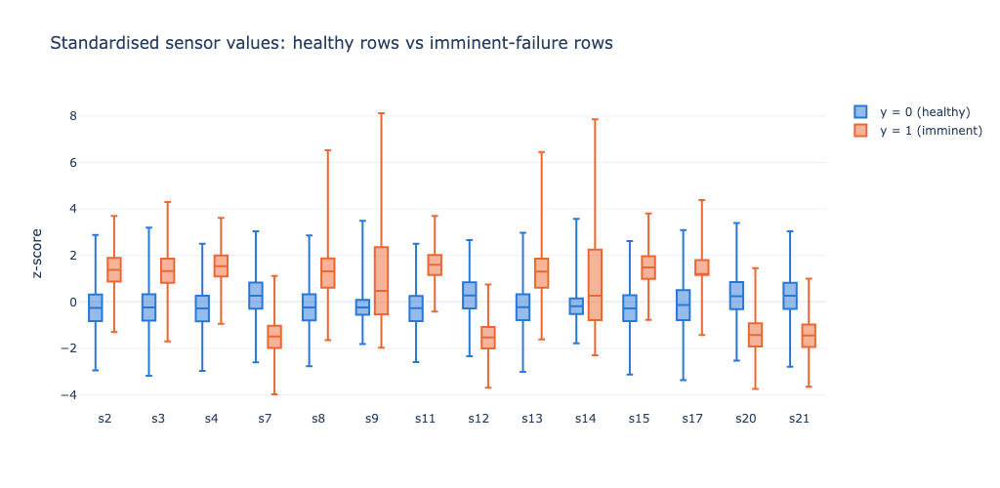

📐 Gap between the two class means, in standard deviations (sorted by size):
s11    1.86
s4     1.81
s12   -1.79
s7    -1.75
s15    1.73
s21   -1.70
s20   -1.68
s17    1.63
s2     1.63
s3     1.57
s8     1.52
s13    1.51
s9     1.17
s14    0.95


In [26]:
# Standardise the sensors (z-score), then reshape to one line per (row, sensor)
z = (train[useful_sensors] - train[useful_sensors].mean()) / train[useful_sensors].std()
z["class"] = train["y"].map({0: "y = 0 (healthy)", 1: "y = 1 (imminent)"})
long = z.melt(id_vars="class", var_name="sensor", value_name="z-score")

# One pair of boxes per sensor: healthy vs imminent failure
fig = px.box(long, x="sensor", y="z-score", color="class", points=False, template=TEMPLATE,
             color_discrete_map={"y = 0 (healthy)": BLUE, "y = 1 (imminent)": ORANGE},
             title="Standardised sensor values: healthy rows vs imminent-failure rows")
fig.update_layout(height=500, legend_title="", xaxis_title="")
fig.show()

# Gap between the two class means, for each sensor
gap = (z[z["class"] == "y = 1 (imminent)"][useful_sensors].mean()
       - z[z["class"] == "y = 0 (healthy)"][useful_sensors].mean())
print("📐 Gap between the two class means, in standard deviations (sorted by size):")
print(gap.reindex(gap.abs().sort_values(ascending=False).index).round(2).to_string())

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- ✅ For 12 of the 14 sensors the two classes are shifted by 1.5 to 1.9 standard deviations.
- 🏅 The best separators are `s11` (+1.86), `s4` (+1.81), `s12` (-1.79) and `s7` (-1.75).

</div>

<a id="sub-8-2"></a>

---

### 🥇 8.2 The 4 sensors that separate best

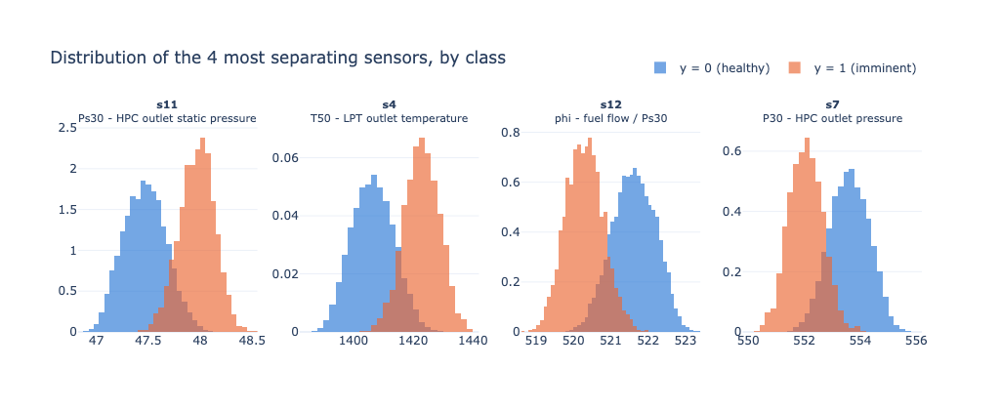

In [27]:
# The 4 sensors with the largest gap between classes
top4 = gap.abs().sort_values(ascending=False).index[:4].tolist()
fig = make_subplots(rows=1, cols=4, subplot_titles=[f"<b>{s}</b><br>{SENSOR_NAMES[s]}" for s in top4])
# For each sensor, one histogram per class
for j, s in enumerate(top4, start=1):
    for cls, color, name in [(0, BLUE, "y = 0 (healthy)"), (1, ORANGE, "y = 1 (imminent)")]:
        fig.add_histogram(x=train.loc[train["y"] == cls, s], histnorm="probability density", nbinsx=40,
                          marker_color=color, opacity=0.65, name=name, showlegend=(j == 1), row=1, col=j)
# Layout, with the legend above the plots
fig.update_annotations(font_size=11)
fig.update_layout(template=TEMPLATE, barmode="overlay", height=420, margin=dict(t=130),
                  title="Distribution of the 4 most separating sensors, by class",
                  legend=dict(orientation="h", yanchor="bottom", y=1.22, xanchor="right", x=1))
fig.show()

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 🔀 The histograms are roughly bell-shaped in each class but **they overlap**: no single sensor with a single threshold separates the classes cleanly.
- 🔔 Roughly Gaussian distributions per class, with a shift in the mean, is a favourable setting for simple models such as logistic regression and Naive Bayes, which makes them sensible baselines.

</div>

<a id="sub-8-3"></a>

---

### 🔬 8.3 Zoom on the two weak sensors: s9 and s14

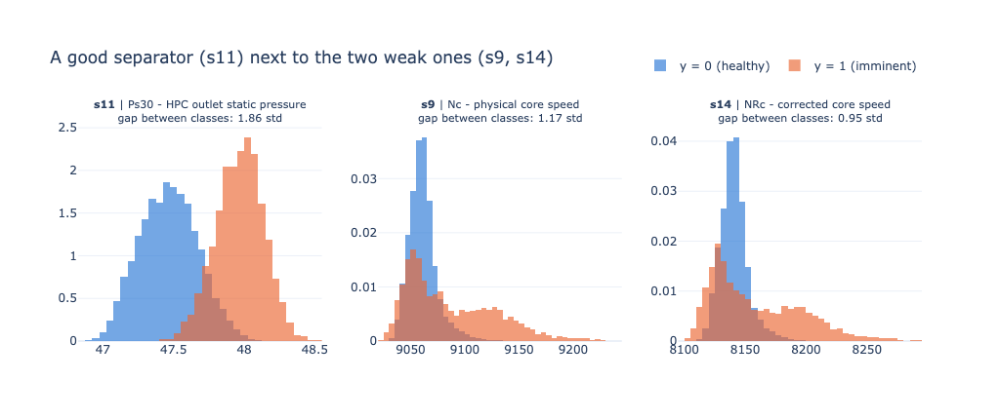

✅ s11 | gap between class means: 1.86 std | spread of y = 1 is 0.8x the spread of y = 0
⚠️ s9  | gap between class means: 1.17 std | spread of y = 1 is 3.1x the spread of y = 0
⚠️ s14 | gap between class means: 0.95 std | spread of y = 1 is 3.2x the spread of y = 0


In [28]:
compare = ["s11", "s9", "s14"]          # one good separator for reference, then the two weak ones
# Spread (standard deviation) of each sensor inside each class
spread = train.groupby("y")[compare].std()

# One panel per sensor, one histogram per class
fig = make_subplots(rows=1, cols=3, subplot_titles=[
    f"<b>{s}</b> | {SENSOR_NAMES[s]}<br>gap between classes: {abs(gap[s]):.2f} std" for s in compare])
for j, s in enumerate(compare, start=1):
    for cls, color, name in [(0, BLUE, "y = 0 (healthy)"), (1, ORANGE, "y = 1 (imminent)")]:
        fig.add_histogram(x=train.loc[train["y"] == cls, s], histnorm="probability density", nbinsx=50,
                          marker_color=color, opacity=0.65, name=name, showlegend=(j == 1), row=1, col=j)
fig.update_annotations(font_size=11)
fig.update_layout(template=TEMPLATE, barmode="overlay", height=430, margin=dict(t=130),
                  title="A good separator (s11) next to the two weak ones (s9, s14)",
                  legend=dict(orientation="h", yanchor="bottom", y=1.22, xanchor="right", x=1))
fig.show()

# Gap between classes, and ratio of the two spreads
for s in compare:
    print(f"{'✅' if abs(gap[s]) > 1.5 else '⚠️'} {s:<3} | gap between class means: {abs(gap[s]):.2f} std | "
          f"spread of y = 1 is {spread.loc[1, s] / spread.loc[0, s]:.1f}x the spread of y = 0")

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- ⚠️ `s9` and `s14` separate less well (1.17 and 0.95) and have a very wide spread in the imminent class, which confirms what we saw in [section 7](#section-7).

👉 **The model will have to combine several sensors.**

</div>

<a id="sub-8-4"></a>

---

### 🔍 8.4 Can we visually separate the two classes in feature space?

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

Two complementary views of **training observations only**: class-wise distributions of two informative sensors, followed by their joint scatter plot. Both use original sensor measurements, without PCA.

</div>


In [ ]:
# Two views of class separation: sensor distributions and original sensor space
import plotly.express as px

# Class labels and colours
class_names = {
    0: "y = 0 (healthy)",
    1: "y = 1 (imminent)"
}
class_colors = {
    "y = 0 (healthy)": BLUE,
    "y = 1 (imminent)": ORANGE
}

# Rank sensors by their standardized mean difference between classes
z = (train[useful_sensors] - train[useful_sensors].mean()) / train[useful_sensors].std()

gap = (
    z.loc[train["y"] == 1].mean()
    - z.loc[train["y"] == 0].mean()
)

ranked = gap.abs().sort_values(ascending=False).index.tolist()

# Select two informative sensors, avoiding a highly correlated pair when possible
s1 = ranked[0]
s2 = next(
    (s for s in ranked[1:] if abs(train[s1].corr(train[s])) < 0.9),
    ranked[1]
)

# Prepare visualization data
plot_data = train[["unit", "cycle", "RUL", "y", s1, s2]].copy()
plot_data["class"] = plot_data["y"].map(class_names)

# Plot 1: Sensor distributions by class
distribution_data = plot_data.melt(
    id_vars=["class"],
    value_vars=[s1, s2],
    var_name="sensor",
    value_name="measurement"
)

fig = px.violin(
    distribution_data,
    x="class",
    y="measurement",
    color="class",
    facet_col="sensor",
    box=True,
    points=False,
    color_discrete_map=class_colors,
    template=TEMPLATE,
    title="Sensor distributions by failure status"
)

fig.update_layout(
    height=550,
    xaxis_title="",
    yaxis_title="Sensor measurement",
    legend_title="",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0)
)

fig.update_xaxes(title_text="")
fig.update_yaxes(matches=None, showticklabels=True)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))

fig.show()

# Plot 2: Class separation using two original sensors
fig = px.scatter(
    plot_data,
    x=s1,
    y=s2,
    color="class",
    color_discrete_map=class_colors,
    opacity=0.35,
    template=TEMPLATE,
    title="Class separation using two informative sensors",
    hover_data=["unit", "cycle", "RUL"]
)

fig.update_traces(marker=dict(size=5))

fig.update_layout(
    height=550,
    xaxis_title=f"{s1} | {SENSOR_NAMES[s1]}",
    yaxis_title=f"{s2} | {SENSOR_NAMES[s2]}",
    legend_title="",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0)
)

fig.show()

print(f"🔍 Sensors displayed: {s1} and {s2}")
print(f"📊 Training observations: {len(plot_data):,}")
print(f"📐 Pearson correlation between sensors: {train[s1].corr(train[s2]):.3f}")


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation — Class Separation in Sensor Space.**

The visualizations explore whether sensor measurements can distinguish **normal operating conditions ($y = 0$)** from **imminent failures ($y = 1$, RUL ≤ 30 cycles)**.

**1. Sensor distributions**
- Differences in distributions indicate that sensors contain information relevant to failure prediction.
- Overlapping distributions suggest that individual sensors may not be sufficient to classify observations reliably.

**2. Class separation in 2D**
- The scatter plot reveals how both classes are distributed according to two informative sensors.
- Distinct regions suggest that classification is feasible, while overlapping regions indicate potentially ambiguous observations.

**3. Implications for modelling**

These observations motivate comparing **linear models (Logistic Regression)** with **nonlinear models (Random Forest, SVM)**.

⚠️ **A 2D visualization cannot establish linear separability in the original 14-dimensional feature space.** Model evaluation is necessary to determine which approach performs best.

</div>


---

<a id="conclusion-8"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 🏁 8.5 Conclusion

🎯 **Goal of the section**: Check whether the sensor values are different for healthy rows ($y = 0$) and for imminent-failure rows ($y = 1$).

✅ **What we found.**
- ✅ **Yes, the two classes look different.** For 12 of the 14 sensors, the average of the $y = 1$ rows is 1.5 to 1.9 standard deviations away from the average of the $y = 0$ rows.
- 🏅 **Best separators.** `s11` (+1.86), `s4` (+1.81), `s12` (-1.79) and `s7` (-1.75).
- 🔀 **But they overlap.** No single sensor with a single threshold separates the classes cleanly: the model will have to combine several sensors.
- 🔍 **Class separation in two dimensions.** The violin plots and two-sensor scatter plot give complementary views of within-class spread and overlap using training observations only. Separation in 2D cannot establish linear separability across all 14 sensors.
- ⚠️ **Two weak sensors.** `s9` and `s14` separate less well (1.17 and 0.95), with imminent-failure values about 3 times more spread out than the healthy ones.
- 🔔 **Shape of the distributions.** Roughly bell-shaped in each class, which makes logistic regression and Naive Bayes sensible baselines.

🔗 **Link with the other sections.** The standardisation introduced here is reused in [section 10](#section-10); the model will have to combine several sensors.

<a href="#section-8">⬆️ Back to the start of the section</a>

</div>

<a id="section-9"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 🚨 9. Outliers: errors or signal?

</div>

<div class="part-block" style="background-color: rgba(26, 127, 100, 0.12); border: 2px solid #1a7f64; border-radius: 6px; padding: 8px 16px; margin-top: 14px; display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 8px;"><span style="font-size: 1.15em;">🧭 <b style="color: #1a7f64;">PART 3 OF 4</b> &nbsp;·&nbsp; <b>What can predict it?</b></span><span><a href="#section-1" title="Part 1: What data do we have?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">1</a><a href="#section-3" title="Part 2: What do we want to predict?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">2</a><a href="#section-6" title="Part 3: What can predict it?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: #1a7f64; color: white;">3</a><a href="#section-12" title="Part 4: What do we give to the models?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">4</a></span></div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- 🎯 **Goal**: Decide whether the extreme values of the sensors must be removed.
- ❓ **Why**: Extreme values are usually removed before modelling. [Section 7](#section-7) showed that ours appear near the failure, so we must check that removing them would not delete the signal.

<a href="#conclusion-9" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">🏁 Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>📋 Plan of the section</b></p>

| Step | What we do |
|---|---|
| [9.1](#sub-9-1) | [Why we use the IQR rule](#sub-9-1) |
| [9.2](#sub-9-2) | [How the rule works, on a generic boxplot](#sub-9-2) |
| [9.3](#sub-9-3) | [The rule applied to one sensor, `s11`](#sub-9-3) |
| [9.4](#sub-9-4) | [The rule applied to the 14 sensors](#sub-9-4) |
| [9.5](#sub-9-5) | [Where the outliers are in the life of the engine](#sub-9-5) |
| [9.6](#conclusion-9) | [Conclusion: what we do with them](#conclusion-9) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

📘 **Context and method**

An **outlier** is a value that is unusually far from the others.

❓ The important question is not how many outliers there are, but **where they are in the life of the engine**: a measurement error can appear at any time, a real degradation appears near the failure.

</div>

<a id="sub-9-1"></a>

---

### 🤔 9.1 Why the IQR rule

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

- 🛡️ **It is not fooled by the outliers themselves.** It is built on quartiles, which are positions in the sorted data, so a few extreme values do not move the limits. A rule built on the mean and standard deviation would be pulled by the very values it is trying to catch.
- 📐 **It does not assume a bell-shaped distribution.** Our sensors are stretched on one side as the engine degrades.
- 📊 **It is the rule behind a boxplot**: the box goes from $Q_1$ to $Q_3$, and the points drawn beyond the whiskers are exactly these outliers.

</div>

<a id="sub-9-2"></a>

---

### ⚙️ 9.2 How it works: the rule on a generic boxplot

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

**In three steps:**
1. Find the box that holds the **middle 50%** of the values, from $Q_1$ to $Q_3$. Its width is the IQR.
2. Step **1.5 times that width** away from each side of the box. These are the two limits.
3. Any value beyond a limit is flagged as an outlier.

**As a formula.** A value $x$ is flagged as an outlier when:

$$x < Q_1 - 1.5 \times \text{IQR} \qquad \text{or} \qquad x > Q_3 + 1.5 \times \text{IQR} \qquad \text{with} \qquad \text{IQR} = Q_3 - Q_1$$

| Symbol | Meaning |
|---|---|
| $x$ | The value of the sensor on one row |
| $Q_1$ | The first quartile: 25% of the values of the sensor are below it |
| $Q_3$ | The third quartile: 75% of the values of the sensor are below it |
| $\text{IQR}$ | The interquartile range: the width of the interval that contains the middle 50% of the values |
| $1.5$ | The usual convention: it is the same rule that draws the whiskers of a boxplot |

👇 **The figure below is a generic boxplot, with made-up values**: $Q_1 = 4$ and $Q_3 = 6$ give $\text{IQR} = 2$, so the limits are $4 - 1.5 \times 2 = 1$ and $6 + 1.5 \times 2 = 9$. The whiskers stop at the last value still inside the limits; the points beyond are the outliers.

</div>

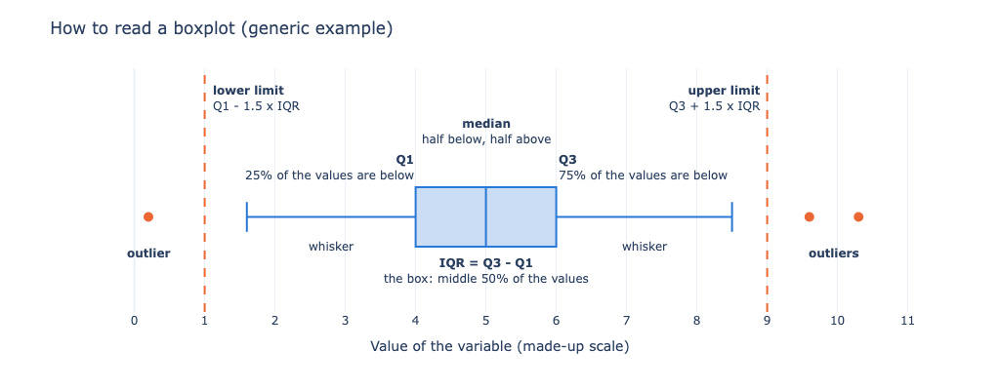

In [19]:
# Generic example with made-up values, only to show how a boxplot is built
g_q1, g_med, g_q3 = 4, 5, 6                                   # the three quartiles
g_iqr = g_q3 - g_q1                                           # IQR = 2
g_low, g_high = g_q1 - 1.5 * g_iqr, g_q3 + 1.5 * g_iqr        # limits: 1 and 9
g_whisker_low, g_whisker_high = 1.6, 8.5                      # last values still inside the limits
g_outliers = [0.2, 9.6, 10.3]                                 # values beyond a limit

# Box, whiskers, outliers and the two limits
fig = go.Figure()
fig.add_box(q1=[g_q1], median=[g_med], q3=[g_q3], lowerfence=[g_whisker_low], upperfence=[g_whisker_high],
            y=[0], orientation="h", width=0.5, fillcolor="rgba(42, 120, 214, 0.25)", line_color=BLUE, showlegend=False)
fig.add_scatter(x=g_outliers, y=[0] * len(g_outliers), mode="markers",
                marker=dict(color=ORANGE, size=10), showlegend=False)
fig.add_vline(x=g_low, line_dash="dash", line_color=ORANGE)
fig.add_vline(x=g_high, line_dash="dash", line_color=ORANGE)

# Labels of each part of the boxplot
note = lambda x, y, text, **kw: fig.add_annotation(x=x, y=y, text=text, showarrow=False, **kw)
note(g_q1, 0.42, "<b>Q1</b><br>25% of the values are below", xanchor="right", align="right")
note(g_med, 0.72, "<b>median</b><br>half below, half above")
note(g_q3, 0.42, "<b>Q3</b><br>75% of the values are below", xanchor="left", align="left")
note((g_q1 + g_q3) / 2, -0.45, "<b>IQR = Q3 - Q1</b><br>the box: middle 50% of the values")
note(g_low, 1.0, "<b>lower limit</b><br>Q1 - 1.5 x IQR", xanchor="left", xshift=6, align="left")
note(g_high, 1.0, "<b>upper limit</b><br>Q3 + 1.5 x IQR", xanchor="right", xshift=-6, align="right")
note((g_q1 + g_whisker_low) / 2, -0.2, "whisker", yshift=-6)
note((g_q3 + g_whisker_high) / 2, -0.2, "whisker", yshift=-6)
note(g_outliers[0], -0.3, "<b>outlier</b>")
note(sum(g_outliers[1:]) / 2, -0.3, "<b>outliers</b>")

# Axes and title
fig.update_xaxes(title="Value of the variable (made-up scale)", range=[-0.8, 11.2], dtick=1)
fig.update_yaxes(visible=False, range=[-0.8, 1.25])
fig.update_layout(template=TEMPLATE, height=400, margin=dict(t=70),
                  title="How to read a boxplot (generic example)")
fig.show()

<a id="sub-9-3"></a>

---

### 🔬 9.3 The rule applied to one sensor: `s11`

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

We now apply the same three steps to a real sensor. The grey bars are all the readings of `s11`, the blue band is the box from $Q_1$ to $Q_3$, and the two orange zones are where a reading is flagged as an outlier.

</div>

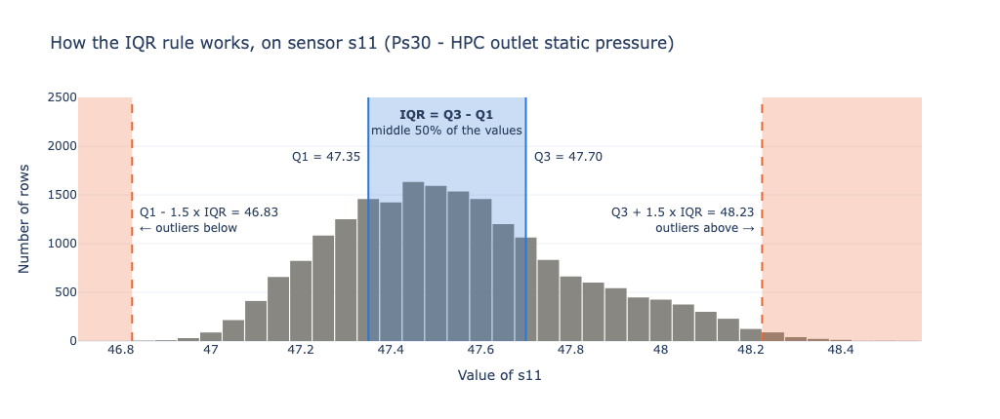

📦 Q1 = 47.35 | Q3 = 47.70 | IQR = 0.35
🚧 Limits: 46.83 and 48.23
🚨 167 rows of s11 fall outside the limits (0.81% of the rows)


In [21]:
s = "s11"                                            # example sensor
# Quartiles, IQR and the two limits of the rule
q1_s, q3_s = train[s].quantile(0.25), train[s].quantile(0.75)
iqr_s = q3_s - q1_s
low, high = q1_s - 1.5 * iqr_s, q3_s + 1.5 * iqr_s
x_min, x_max = min(train[s].min(), low) - 0.12, train[s].max() + 0.05

# Histogram of all the readings of the sensor
fig = px.histogram(train, x=s, nbins=60, color_discrete_sequence=[GREY], template=TEMPLATE,
                   title=f"How the IQR rule works, on sensor {s} ({SENSOR_NAMES[s]})")

# The box: from Q1 to Q3, it holds the middle 50% of the values
fig.add_vrect(x0=q1_s, x1=q3_s, fillcolor=BLUE, opacity=0.25, line_width=0)
fig.add_vline(x=q1_s, line_color=BLUE)
fig.add_vline(x=q3_s, line_color=BLUE)
fig.add_annotation(x=(q1_s + q3_s) / 2, y=2250, showarrow=False, text="<b>IQR = Q3 - Q1</b><br>middle 50% of the values")
fig.add_annotation(x=q1_s, y=1900, showarrow=False, xanchor="right", xshift=-6, text=f"Q1 = {q1_s:.2f}")
fig.add_annotation(x=q3_s, y=1900, showarrow=False, xanchor="left", xshift=6, text=f"Q3 = {q3_s:.2f}")

# The limits: 1.5 x IQR away from the box. Beyond them, a value is an outlier
fig.add_vrect(x0=x_min, x1=low, fillcolor=ORANGE, opacity=0.25, line_width=0)
fig.add_vrect(x0=high, x1=x_max, fillcolor=ORANGE, opacity=0.25, line_width=0)
fig.add_vline(x=low, line_dash="dash", line_color=ORANGE)
fig.add_vline(x=high, line_dash="dash", line_color=ORANGE)
fig.add_annotation(x=low, y=1250, showarrow=False, xanchor="left", xshift=6, align="left",
                   text=f"Q1 - 1.5 x IQR = {low:.2f}<br>← outliers below")
fig.add_annotation(x=high, y=1250, showarrow=False, xanchor="right", xshift=-6, align="right",
                   text=f"Q3 + 1.5 x IQR = {high:.2f}<br>outliers above →")

# Axes
fig.update_layout(height=430, bargap=0.05, xaxis_range=[x_min, x_max], yaxis_range=[0, 2500],
                  xaxis_title=f"Value of {s}", yaxis_title="Number of rows")
fig.show()

# Number of readings beyond the limits
n_out = ((train[s] < low) | (train[s] > high)).sum()
print(f"📦 Q1 = {q1_s:.2f} | Q3 = {q3_s:.2f} | IQR = {iqr_s:.2f}")
print(f"🚧 Limits: {low:.2f} and {high:.2f}")
print(f"🚨 {n_out} rows of {s} fall outside the limits ({n_out / len(train) * 100:.2f}% of the rows)")

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 📦 For `s11`, the middle 50% of the values lie between $Q_1 = 47.35$ and $Q_3 = 47.70$, so $\text{IQR} = 0.35$.
- 🚧 The limits are 46.83 and 48.23: a reading outside them is flagged as an outlier.
- 🚨 167 rows are flagged (0.81% of the rows), all of them above the upper limit, which is the direction `s11` drifts as the engine degrades.

</div>

<a id="sub-9-4"></a>

---

### 🧮 9.4 Outliers of each sensor

In [29]:
# IQR rule on each of the 14 sensors: True where a value is an outlier
q1, q3 = train[useful_sensors].quantile(0.25), train[useful_sensors].quantile(0.75)
iqr = q3 - q1
is_outlier = (train[useful_sensors] < q1 - 1.5 * iqr) | (train[useful_sensors] > q3 + 1.5 * iqr)

# Per sensor: number of outliers, and where they are in the life of the engine
outliers = pd.DataFrame({
    "outlier rows": is_outlier.sum(),
    "% of rows": (is_outlier.mean() * 100).round(2),
    "% of them in last 30 cycles": [round(train.loc[is_outlier[s], "y"].mean() * 100, 1) if is_outlier[s].any() else 0
                                    for s in useful_sensors],
    "median RUL of outliers": [train.loc[is_outlier[s], "RUL"].median() for s in useful_sensors],
})
# Key figures
print(f"🚨 Rows flagged on at least one sensor: {is_outlier.any(axis=1).sum():,} "
      f"({is_outlier.any(axis=1).mean() * 100:.1f}% of train)")
print(f"🎯 Share of class y = 1 in the whole train set: {train['y'].mean() * 100:.1f}%")
outliers.sort_values("% of rows", ascending=False)

🚨 Rows flagged on at least one sensor: 2,431 (11.8% of train)
🎯 Share of class y = 1 in the whole train set: 15.0%


,outlier rows,% of rows,% of them in last 30 cycles,median RUL of outliers
s9,1686,8.17,71.2,20.0
s14,1543,7.48,73.3,19.0
s8,320,1.55,97.2,5.0
s11,167,0.81,100.0,2.0
s3,165,0.80,86.7,6.0
s13,161,0.78,97.5,4.0
s12,146,0.71,100.0,3.0
s21,136,0.66,92.6,4.0
s2,128,0.62,89.1,6.0
s4,120,0.58,99.2,3.0


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 🔢 2,431 rows (11.8%) are flagged on at least one sensor. For 12 sensors this concerns less than 1.6% of rows; `s9` and `s14` stand out with about 8%.
- 🎯 **The outliers are concentrated at the end of life.** Depending on the sensor, 71% to 100% of the flagged rows are in the last 30 cycles, although this class is only 15% of the data, and their median RUL is between 2 and 20 cycles.

</div>

<a id="sub-9-5"></a>

---

### 📍 9.5 Where the outliers are in the life of the engine

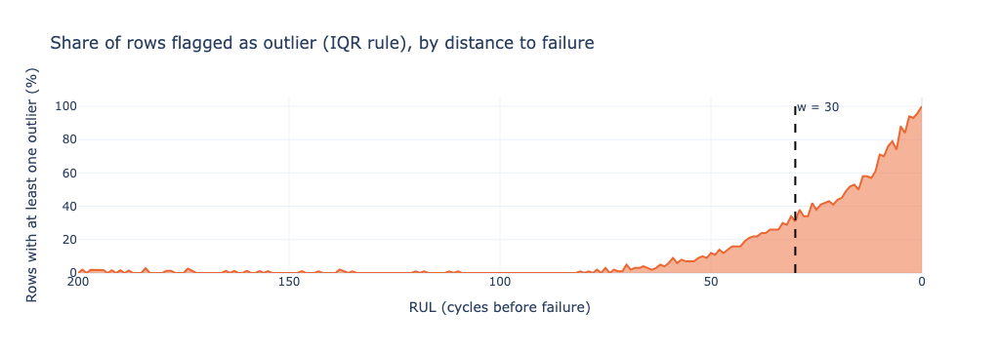

In [30]:
# Share of rows with at least one outlier, at each number of cycles left
flagged = train.assign(n_flags=is_outlier.sum(axis=1))
by_rul = flagged[flagged["RUL"] <= HORIZON].groupby("RUL")["n_flags"].apply(lambda x: (x > 0).mean() * 100)

# Area chart, with the failure on the right
fig = px.area(by_rul.reset_index(), x="RUL", y="n_flags", template=TEMPLATE, color_discrete_sequence=[ORANGE],
              title="Share of rows flagged as outlier (IQR rule), by distance to failure")
fig.add_vline(x=W, line_dash="dash", line_color="black", annotation_text=f"w = {W}")
fig.update_xaxes(autorange="reversed", title="RUL (cycles before failure)")
fig.update_yaxes(title="Rows with at least one outlier (%)")
fig.show()

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 📈 The curve makes it obvious: almost no row is flagged more than 75 cycles before failure, then the share rises steadily to about 100% on the failure row.

</div>

<a id="conclusion-9"></a>

---

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 🏁 9.6 Conclusion: what we do with the outliers

🎯 **Goal of the section**: Decide whether the extreme values of the sensors must be removed.

✅ **What we found.**
- 🔎 **What the IQR rule flags.** 2,431 training rows (11.8%) on at least one sensor: less than 1.6% of the rows for 12 sensors, about 8% for `s9` and `s14`.
- 📍 **Where they are.** 71% to 100% of the flagged values are in the last 30 cycles, and the share of flagged rows rises to about 100% on the failure row.

✅ **Decision: we do not remove or clip the outliers.**

🧠 They are not measurement errors, they are the degradation itself. Removing them would delete exactly the rows the model must learn to recognise.

🔗 **Link with the other sections.** These rows are the $y = 1$ rows of [section 5](#section-5), the ones the model must learn to recognise.

<a href="#section-9">⬆️ Back to the start of the section</a>

</div>

<a id="section-10"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 🔗 10. Are the sensors redundant?

</div>

<div class="part-block" style="background-color: rgba(26, 127, 100, 0.12); border: 2px solid #1a7f64; border-radius: 6px; padding: 8px 16px; margin-top: 14px; display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 8px;"><span style="font-size: 1.15em;">🧭 <b style="color: #1a7f64;">PART 3 OF 4</b> &nbsp;·&nbsp; <b>What can predict it?</b></span><span><a href="#section-1" title="Part 1: What data do we have?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">1</a><a href="#section-3" title="Part 2: What do we want to predict?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">2</a><a href="#section-6" title="Part 3: What can predict it?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: #1a7f64; color: white;">3</a><a href="#section-12" title="Part 4: What do we give to the models?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">4</a></span></div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- 🎯 **Goal**: Find the sensors that carry the same information.
- ❓ **Why**: [Section 7](#section-7) showed the sensors drifting together. If they all say the same thing, some are unnecessary, and redundant inputs harm some models.

<a href="#conclusion-10" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">🏁 Go to the conclusion of this section</a>

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

📘 **Context and method**

📚 A dataset often contains features that are **redundant** or unrelated to the value to predict, and feature selection removes them. The **Pearson correlation coefficient** is one of the filter methods used for this.

<hr style="border: none; border-top: 1px solid rgba(31, 119, 180, 0.30); margin: 10px 0;">

🧮 **What it is.** We already standardised the sensors in [section 8](#section-8):

$$z = \frac{x - \mu}{\sigma}$$

The Pearson correlation between two sensors $X$ and $Y$ is the **covariance of their standardised values**:

$$r_{XY} = \text{cov}(z_X, z_Y) = \frac{1}{n-1}\sum_{i=1}^{n} z_{X,i}\; z_{Y,i}$$

| Symbol | Meaning |
|---|---|
| $X$, $Y$ | The two sensors being compared (for example `s11` and `s12`) |
| $z_{X,i}$, $z_{Y,i}$ | The standardised values of sensors $X$ and $Y$ on row $i$ |
| $n$ | The number of rows (20,631) |
| $r_{XY}$, or simply $r$ | The **Pearson correlation coefficient** between $X$ and $Y$, always between $-1$ and $+1$. Its sign gives the direction of the link, its size gives the strength. |
| $\lvert r\rvert$ | The **absolute value** of $r$, i.e. $r$ without its sign: $\lvert -0.85\rvert = 0.85$. It measures the strength of the link, whatever its direction. Same vertical bars as in the Manhattan distance. |

The **correlation matrix** below is therefore the covariance matrix of the 14 standardised sensors.

<hr style="border: none; border-top: 1px solid rgba(31, 119, 180, 0.30); margin: 10px 0;">

📖 **How to read it:**
- 🔴 $r$ close to $+1$: the two sensors move together.
- 🔵 $r$ close to $-1$: they move in opposite directions.
- ⚪ $r$ close to $0$: no linear link.

📌 Two sensors with $|r|$ close to 1 (so $r$ close to $+1$ or to $-1$) are **redundant**: one of them is enough.

</div>

<a id="sub-10-1"></a>

---

### 🗺️ 10.1 The correlation matrix, sensors grouped by family

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

To make the groups visible, the sensors are not listed in numerical order. They are grouped in the three families seen in [section 7](#section-7) and [section 8](#section-8):

| Family | Sensors | How we recognise it |
|---|---|---|
| 📈 **Rise before failure** | 8 sensors: `s2`, `s3`, `s4`, `s8`, `s11`, `s13`, `s15`, `s17` | their correlation with the RUL is negative |
| 📉 **Fall before failure** | 4 sensors: `s7`, `s12`, `s20`, `s21` | their correlation with the RUL is positive |
| ❔ **`s9` and `s14`** | Nc (physical core speed) and NRc (corrected core speed) | the two unreliable sensors of sections 7 and 8 |

Each family is surrounded by a **black frame** on the diagonal. The value written in a cell is $r$ for the two sensors of its row and column.

</div>

In [1]:
# Pearson correlation between every pair of sensors
corr = train[useful_sensors].corr()

# The three families seen in sections 7 and 8, used to order the rows and columns of the matrix
direction = train[useful_sensors].corrwith(train["RUL"])     # r < 0 with the RUL: the sensor rises as the failure approaches
apart = ["s9", "s14"]                                          # the two unreliable sensors
rising = [s for s in useful_sensors if direction[s] < 0 and s not in apart]
falling = [s for s in useful_sensors if direction[s] > 0 and s not in apart]
families = {"📈 rise before failure": rising, "📉 fall before failure": falling, "❔ s9, s14": apart}
order = rising + falling + apart
labels = [f"{s} · {SENSOR_NAMES[s].split(' - ')[0]}" for s in order]      # code and short name, e.g. "s11 · Ps30"

# Heatmap of the correlation matrix, sensors grouped by family
ordered = corr.loc[order, order]
fig = go.Figure(go.Heatmap(
    z=ordered.values, x=labels, y=labels, zmin=-1, zmax=1, colorscale="RdBu_r", xgap=1, ygap=1,
    text=ordered.values, texttemplate="%{text:.2f}", textfont_size=11,
    colorbar=dict(title="r", tickvals=[-1, -0.5, 0, 0.5, 1])))

# One black frame per family on the diagonal, with its name above the matrix
start = 0
for name, members in families.items():
    end = start + len(members)
    fig.add_shape(type="rect", x0=start - 0.5, x1=end - 0.5, y0=start - 0.5, y1=end - 0.5,
                  line=dict(color="black", width=3))
    fig.add_annotation(x=(start + end - 1) / 2, y=-0.5, yshift=14, showarrow=False, text=f"<b>{name}</b>")
    start = end

# Layout: first sensor at the top, square cells
fig.update_yaxes(autorange="reversed")
fig.update_xaxes(tickangle=-45)
fig.update_layout(template=TEMPLATE, height=720, margin=dict(t=110),
                  title="Pearson correlation between the 14 sensors, grouped by family")
fig.show()

# Size of each family
for name, members in families.items():
    print(f"{name:<24}: {len(members)} sensors | {', '.join(members)}")

NameError: name 'train' is not defined

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- 🟥 **Inside the two large frames, everything is red.** Two sensors of the same family move together: $r$ from $+0.60$ to $+0.83$ among the 8 that rise, and from $+0.69$ to $+0.81$ among the 4 that fall.
- 🟦 **Between the two large frames, everything is blue.** A sensor that rises and a sensor that falls move in opposite directions: $r$ from $-0.63$ to $-0.85$. The link is as strong as inside a family, only the sign changes.
- 🧱 **So these 12 sensors form one single block**: every one of them is linked to the 11 others with $\lvert r\rvert \ge 0.60$.
- ⬜ **The rows and columns of `s9` and `s14` are pale.** Their link with the 12 others is weak ($\lvert r\rvert$ from 0.03 to 0.34).
- 👯 **Their own small frame is dark red.** `s9` (Nc, physical core speed) and `s14` (NRc, corrected core speed) are almost identical to each other: $r = +0.96$.
- 🧠 The block of 12 is expected: there is a single fault, so all these sensors are different views of the same hidden variable, the health of the engine.

⚠️ **Consequences for modelling.** The features are strongly collinear:
- 📉 the coefficients of a logistic regression become unstable and hard to interpret;
- 🚫 the independence assumption of Naive Bayes is broken.

👉 This justifies the **feature selection** step that follows.

</div>

---

<a id="conclusion-10"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 🏁 10.2 Conclusion

🎯 **Goal of the section**: Find the sensors that carry the same information.

✅ **What we found.**
- 🧱 **Yes, the sensors are redundant.** Twelve of them are correlated with each other, with $\lvert r\rvert$ between 0.6 and 0.85 (for example `s11` and `s12`: -0.85, `s4` and `s11`: 0.83). The 8 that rise and the 4 that fall form one single block: only the sign of $r$ differs.
- 👯 **A separate pair.** `s9` and `s14` are almost identical to each other ($r = 0.96$, the strongest link of the matrix) and weakly correlated with the rest ($\lvert r\rvert$ from 0.03 to 0.34, the weakest links): one of the two is enough.
- 🧠 **Why.** There is a single fault, so all these sensors are different views of the same thing: the health of the engine.
- ⚠️ **Consequence for modelling.** Strongly correlated features make the coefficients of a logistic regression unstable and break the independence assumption of Naive Bayes.

🔗 **Link with the other sections.** This justifies selecting features, which starts with the ranking of [section 11](#section-11).

<a href="#section-10">⬆️ Back to the start of the section</a>

</div>

<a id="section-11"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 🏆 11. Which sensors are the most linked to the time left before failure?

</div>

<div class="part-block" style="background-color: rgba(26, 127, 100, 0.12); border: 2px solid #1a7f64; border-radius: 6px; padding: 8px 16px; margin-top: 14px; display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 8px;"><span style="font-size: 1.15em;">🧭 <b style="color: #1a7f64;">PART 3 OF 4</b> &nbsp;·&nbsp; <b>What can predict it?</b></span><span><a href="#section-1" title="Part 1: What data do we have?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">1</a><a href="#section-3" title="Part 2: What do we want to predict?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">2</a><a href="#section-6" title="Part 3: What can predict it?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: #1a7f64; color: white;">3</a><a href="#section-12" title="Part 4: What do we give to the models?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">4</a></span></div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- 🎯 **Goal**: Rank the 14 sensors by how useful they are to predict the failure.
- ❓ **Why**: We have to finish with a decision: which sensors are given to the models.

<a href="#conclusion-11" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">🏁 Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>📋 Plan of the section</b></p>

| Step | What we do |
|---|---|
| [11.1](#sub-11-1) | [The two scenarios on real data: a useful sensor and a useless column](#sub-11-1) |
| [11.2](#sub-11-2) | [Ranking of the 14 sensors](#sub-11-2) |
| [11.3](#sub-11-3) | [The features we keep for modelling](#sub-11-3) |
| [11.4](#conclusion-11) | [Conclusion](#conclusion-11) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

📘 **Context and method**

🎯 **Why this step.** We have 14 sensors left. Before modelling, we want to know **which ones are the most useful to predict the failure**, so that we can decide which to give to the model.

<hr style="border: none; border-top: 1px solid rgba(31, 119, 180, 0.30); margin: 10px 0;">

💡 **The idea.** A sensor is useful if its value **changes as the engine gets closer to failure**. For example, `s11` rises steadily during the last flights: reading `s11` tells us something about how many cycles are left. A sensor whose value does not depend on the cycles left tells us nothing.

<hr style="border: none; border-top: 1px solid rgba(31, 119, 180, 0.30); margin: 10px 0;">

🛠️ **How.** We use a **filter method**:
1. For each sensor, compute its **Pearson correlation with the target** (same coefficient as in [section 10](#section-10)).
2. **Rank** the sensors by the strength of that correlation, $|r|$.
3. The sensors at the top of the ranking are the best candidates; those at the bottom can be dropped.

We compute it against the two forms of our target:
- ⏳ the column `RUL` (number of cycles left before failure);
- 🏷️ the label `y` (1 if the failure is imminent).

<hr style="border: none; border-top: 1px solid rgba(31, 119, 180, 0.30); margin: 10px 0;">

📖 **How to read the result.**
- $|r|$ close to 1: the sensor's value changes almost in step with the number of cycles left. **Useful.**
- $|r|$ close to 0: the sensor's value does not depend on the number of cycles left. **Candidate for removal.**
- ➖ A negative sign with `RUL` means the sensor **rises** as the failure approaches.

ℹ️ Nothing is transformed here: each sensor only receives a score. This is not a PCA.

</div>

<a id="sub-11-1"></a>

---

### 🔎 11.1 The two scenarios, on real data

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

Each grey dot is one row (one flight). The x-axis is the number of cycles left before failure, with the failure on the right. The blue line is the average value at each number of cycles left.

</div>

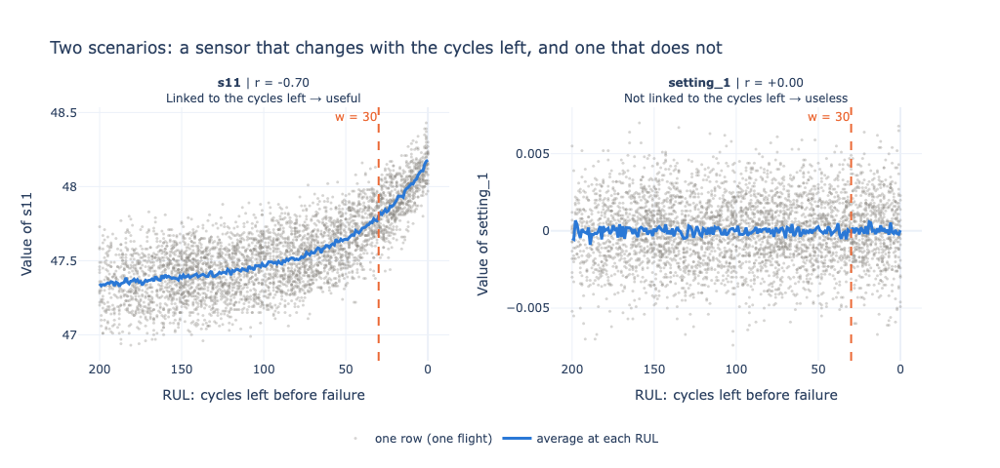

✅ s11        r = -0.696 | |r| = 0.696
❌ setting_1  r = -0.003 | |r| = 0.003


In [36]:
# The two columns compared, and the caption of each
examples = {
    "s11": "Linked to the cycles left → useful",
    "setting_1": "Not linked to the cycles left → useless",
}
# A sample of rows, and the average at each number of cycles left
sample = train[train["RUL"] <= HORIZON].sample(4000, random_state=0)       # 4,000 rows are enough to see the shape
trend = train[train["RUL"] <= HORIZON].groupby("RUL")[list(examples)].mean()

# One panel per column: dots = rows, line = average
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.12, subplot_titles=[
    f"<b>{col}</b> | r = {round(train[col].corr(train['RUL']), 2) + 0:+.2f}<br>{text}" for col, text in examples.items()])
for j, col in enumerate(examples, start=1):
    fig.add_scatter(x=sample["RUL"], y=sample[col], mode="markers", marker=dict(color=GREY, size=3, opacity=0.35),
                    name="one row (one flight)", showlegend=(j == 1), row=1, col=j)
    fig.add_scatter(x=trend.index, y=trend[col], mode="lines", line=dict(color=BLUE, width=3),
                    name="average at each RUL", showlegend=(j == 1), row=1, col=j)
    # Boundary of the label: rows to the right of this line have y = 1 (imminent failure)
    fig.add_vline(x=W, line_dash="dash", line_color=ORANGE, line_width=2,
                  annotation_text=f"w = {W}", annotation_position="top left", annotation_font_color=ORANGE,
                  row=1, col=j)
    fig.update_yaxes(title_text=f"Value of {col}", row=1, col=j)
# Axes, title and legend
fig.update_xaxes(autorange="reversed", title_text="RUL: cycles left before failure")
fig.update_annotations(font_size=12)
fig.update_layout(template=TEMPLATE, height=480, margin=dict(t=110, b=110),
                  title="Two scenarios: a sensor that changes with the cycles left, and one that does not",
                  legend=dict(orientation="h", yanchor="top", y=-0.25, xanchor="center", x=0.5,
                              bgcolor="rgba(0,0,0,0)"))
fig.show()

# Correlation of each column with the RUL
for col in examples:
    r = train[col].corr(train["RUL"])
    print(f"{'✅' if abs(r) > 0.5 else '❌'} {col:<10} r = {r:+.3f} | |r| = {abs(r):.3f}")

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**
- ✅ **`s11` (Ps30, HPC outlet static pressure), $|r| = 0.70$.** The cloud of dots climbs as we move right, towards the failure: about 47.3 with 200 cycles left, about 48.2 at failure. If we read a high value of `s11`, the engine is probably close to failing. **This sensor helps to predict.**
- ❌ **`setting_1` (operational setting 1), $|r| = 0.00$.** The cloud is a flat band: the values are spread the same way whether 200 cycles are left or none. Reading `setting_1` tells us nothing about how close the failure is. **This column does not help.**

👉 The chart below gives this same score, $|r|$, to each of the 14 sensors and ranks them.

</div>

<a id="sub-11-2"></a>

---

### 🏅 11.2 Ranking the 14 sensors

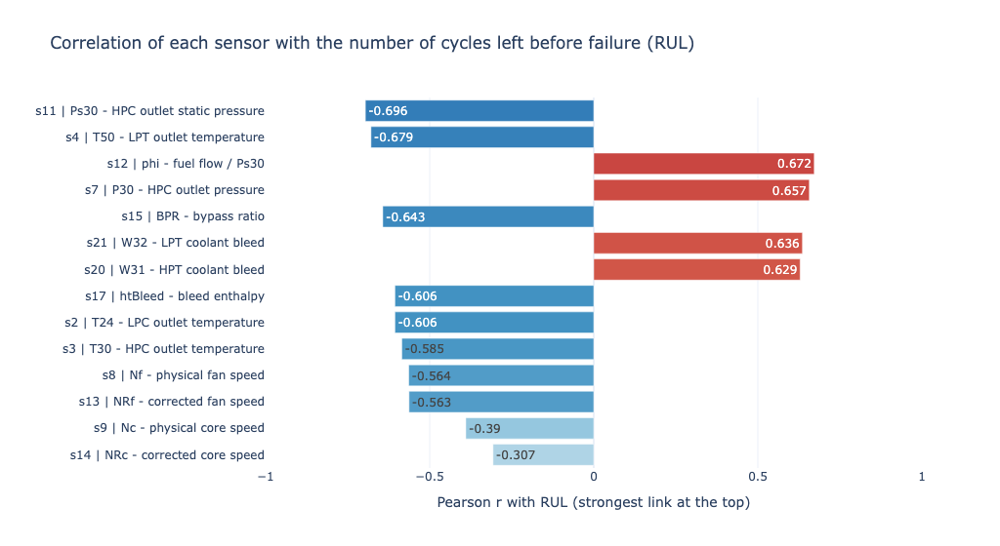

,Pearson r with RUL,|r| with RUL,Pearson r with y
s11,-0.696,0.696,0.666
s4,-0.679,0.679,0.648
s12,0.672,0.672,-0.640
s7,0.657,0.657,-0.626
s15,-0.643,0.643,0.619
s21,0.636,0.636,-0.606
s20,0.629,0.629,-0.600
s17,-0.606,0.606,0.583
s2,-0.606,0.606,0.581
s3,-0.585,0.585,0.562


In [39]:
# Correlation of each sensor with the RUL and with the label y
target_corr = pd.DataFrame({
    "Pearson r with RUL": train[useful_sensors].corrwith(train["RUL"]),
    "Pearson r with y": train[useful_sensors].corrwith(train["y"]),
}).round(3)
# Rank the sensors by the strength of the link
target_corr["|r| with RUL"] = target_corr["Pearson r with RUL"].abs()
target_corr = target_corr.sort_values("|r| with RUL")      # weakest first: Plotly draws the first row at the bottom
target_corr["sensor"] = [f"{s} | {SENSOR_NAMES[s]}" for s in target_corr.index]

# Horizontal bars: blue = rises towards failure, red = falls
fig = px.bar(target_corr, x="Pearson r with RUL", y="sensor", orientation="h",
             color="Pearson r with RUL", color_continuous_scale="RdBu_r", range_color=[-1, 1],
             text="Pearson r with RUL", template=TEMPLATE,
             title="Correlation of each sensor with the number of cycles left before failure (RUL)")
fig.update_layout(height=560, coloraxis_showscale=False, yaxis_title="", xaxis_range=[-1, 1],
                  xaxis_title="Pearson r with RUL (strongest link at the top)")
fig.show()

# Ranking table, strongest link first
target_corr.iloc[::-1][["Pearson r with RUL", "|r| with RUL", "Pearson r with y"]]

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

💡 **Interpretation.**

📖 **Reading the chart.**
- ⬆️ The sensors are ranked by $|r|$: the strongest link with the RUL is at the top.
- 🔵 A bar to the **left** ($r < 0$) is a sensor that **rises** as the failure approaches.
- 🔴 A bar to the **right** ($r > 0$) is a sensor that **falls** as the failure approaches.

📊 **What it shows.**
- 🥇 **The most useful sensors** ($|r|$ of about 0.7):
  - `s11` (Ps30, HPC outlet static pressure): $r = -0.70$
  - `s4` (T50, LPT outlet temperature): $r = -0.68$
  - `s12` (phi, fuel flow / Ps30): $r = +0.67$
  - `s7` (P30, HPC outlet pressure): $r = +0.66$
- 🧱 **A compact group.** Twelve of the 14 sensors have $|r|$ between 0.56 and 0.70: they are almost equally useful, which fits with their being redundant with each other ([section 10](#section-10)).
- 🥉 **The two weakest:** `s9` (Nc, physical core speed, $r = -0.39$) and `s14` (NRc, corrected core speed, $r = -0.31$). They were already the unreliable ones in sections [7](#section-7) and [8](#section-8), and they duplicate each other ([section 10](#section-10)): they are the first candidates for removal.
- 🏷️ **Same ranking with the label `y`** (last column of the table). The values are slightly lower (0.67 for `s11`) and of opposite sign, which is expected: when the RUL goes down, `y` goes from 0 to 1.
- 📈 **A limit to keep in mind.** Pearson measures how close a link is to a straight line, and ours is curved: in [section 7](#section-7) the sensors stay flat, then bend as the failure approaches. The scores are therefore a little **lower than the real strength** of the link. The **ranking stays valid**: it is the same as the one given by the gap between the two classes in [section 8](#section-8) (`s11`, `s4`, `s12`, `s7` first; `s9` and `s14` last).
- 🧩 **No sensor is enough alone.** None exceeds $|r| = 0.70$: there is information, but it has to be combined.

👉 **For modelling:** the curved shape is also a reason to compare linear models (logistic regression) with non-linear ones (decision trees, ensembles, SVM with a kernel).

</div>

<a id="sub-11-3"></a>

---

### ✅ 11.3 The features we keep for modelling

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

**Decision: the models will be given the 14 sensors as features.**

`s2`, `s3`, `s4`, `s7`, `s8`, `s9`, `s11`, `s12`, `s13`, `s14`, `s15`, `s17`, `s20`, `s21`

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

🤔 **Why keep `s9` and `s14`, the two weakest sensors?**
- 📉 They are the weakest of the ranking ($r = -0.39$ and $-0.31$ with the RUL) and they do not behave the same way in every engine (sections [7](#section-7) and [8](#section-8)), so they are the first candidates for removal.
- 🧩 But **`s9` and `s14` are weakly correlated with the other 12 sensors** ([section 10](#section-10)), so they may bring information the others do not.
- ⚖️ The ranking of this section scores each sensor **alone**: it cannot tell whether a sensor helps once it is **combined** with the others.

🧪 **This will be tested in the modelling stage**: the models will be compared with and without `s9` and `s14`, and these two sensors will be removed if necessary.

🚫 **What is not a feature:**

| Column | Why it is left out |
|---|---|
| `unit` | It is only the number of the engine |
| `RUL`, `y` | They are the target, and what the target is built from (target leakage, [section 5](#section-5)) |
| `setting_3`, `s1`, `s5`, `s6`, `s10`, `s16`, `s18`, `s19` | They never change ([section 6](#section-6)) |
| `setting_1`, `setting_2` | They are noise, with no link with the RUL ([section 6](#section-6)) |
| `cycle` | Not in this starting set: the age of an engine alone is not enough to predict its failure ([section 4](#section-4)). It can be tested as an extra feature in the modelling stage. |

</div>

---

<a id="conclusion-11"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 🏁 11.4 Conclusion

🎯 **Goal of the section**: Rank the 14 sensors by how useful they are to predict the failure.

✅ **What we found.**
- 🥇 **The most useful sensors.** `s11` ($r = -0.70$), `s4` ($-0.68$), `s12` ($+0.67$) and `s7` ($+0.66$) have the strongest link with the RUL.
- 🧱 **A compact group.** Twelve of the 14 sensors have $\lvert r\rvert$ between 0.56 and 0.70.
- 🥉 **The two weakest.** `s9` ($-0.39$) and `s14` ($-0.31$): they are the first candidates for removal.
- 🏷️ **Same ranking with the label $y$**, with slightly lower values.
- 📈 **A limit.** Pearson only measures the straight-line part of a link and ours is curved, so the scores are a little low; the ranking stays valid, it matches the one of [section 8](#section-8).
- 🧩 **No sensor is enough alone**: none exceeds $\lvert r\rvert = 0.70$, the information has to be combined.
- ✅ **Features kept for modelling: the 14 sensors** (`s2`, `s3`, `s4`, `s7`, `s8`, `s9`, `s11`, `s12`, `s13`, `s14`, `s15`, `s17`, `s20`, `s21`). `s9` and `s14` are kept although they are the weakest: they are weakly correlated with the other 12 sensors, so they may bring information the others do not. This will be tested in the modelling stage, and they will be removed if necessary.

🔗 **Link with the other sections.** This ranking is the starting point for choosing the features in the modelling stage ([section 12](#section-12)).

<a href="#section-11">⬆️ Back to the start of the section</a>

</div>

<a id="section-12"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 🧭 12. What we learned, and what it means for modelling

</div>

<div class="part-block" style="background-color: rgba(26, 127, 100, 0.12); border: 2px solid #1a7f64; border-radius: 6px; padding: 8px 16px; margin-top: 14px; display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 8px;"><span style="font-size: 1.15em;">🧭 <b style="color: #1a7f64;">PART 4 OF 4</b> &nbsp;·&nbsp; <b>What do we give to the models?</b></span><span><a href="#section-1" title="Part 1: What data do we have?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">1</a><a href="#section-3" title="Part 2: What do we want to predict?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">2</a><a href="#section-6" title="Part 3: What can predict it?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: transparent; color: #1a7f64;">3</a><a href="#section-12" title="Part 4: What do we give to the models?" style="display: inline-block; min-width: 26px; text-align: center; padding: 2px 8px; margin-left: 6px; border-radius: 12px; border: 2px solid #1a7f64; font-weight: 700; text-decoration: none; background-color: #1a7f64; color: white;">4</a></span></div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- ❓ **Why**: The decisions are scattered across eleven sections; the next stage needs them in one place.

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

| | Finding | Evidence | Decision for the next stage |
|---|---|---|---|
| 🧹 | The data is clean | 0 missing value, 0 duplicate, all columns numeric | No imputation, no encoding |
| ⏳ | Lifetimes vary a lot | 128 to 362 cycles | Age is not enough, the sensors are needed |
| 🆚 | Train and test are different engines from the same population | 0 shared row, same median lifetime (199 cycles) | **Validate on engines the model has never seen**: all the rows of an engine on the same side, training or validation ([section 4.3](#sub-4-3)) |
| 🎯 | The target must be built | $y = 1$ if $\text{RUL} \le 30$ | Keep `RUL` out of the features (target leakage) |
| ⚖️ | The classes are imbalanced | 15% of training rows have $y = 1$ | Judge the models on recall, precision, F1 and AUC, not on accuracy alone |
| 🗑️ | 8 columns carry no information | one value covers 98% to 100% of their rows | Drop them, and the 2 noisy settings |
| 📏 | The sensors are on different scales | from about 8 to about 9,000 | Standardise before k-NN, SVM and logistic regression |
| 📉 | The degradation is visible but noisy | flat, then drifting trajectories ([section 7](#section-7)) | The sensors carry the signal, but a single row is an imprecise picture of the engine |
| 🚨 | The outliers are end-of-life values | 71% to 100% of them are in the last 30 cycles | Keep them |
| 🔗 | The sensors are redundant | $\lvert r\rvert$ from 0.6 to 0.85 between 12 sensors; 0.96 between `s9` and `s14` | Select features |
| 🏆 | Some sensors are more useful than others | `s11`, `s4`, `s12`, `s7` at $\lvert r\rvert \approx 0.7$ with the RUL; `s9`, `s14` below 0.4 | Start from the top of the ranking; `s9` and `s14` are the first candidates for removal. **We keep the 14 sensors as features**: `s9` and `s14` are weakly correlated with the other 12, so they may bring information the others do not; this will be tested, and they will be removed if necessary |
| 📈 | The link between sensors and RUL is curved | flat then bending trajectories ([section 7](#section-7)) | Compare linear and non-linear models |

❓ **Why validate on engines the model has never seen?** The test file only contains new engines. If the training rows are split at random, 100 engines out of 100 have rows on both sides, and 97% of the validation rows have their previous or next flight in the training set. The validation score would then say nothing about a new engine ([section 4.3](#sub-4-3)).

</div>

<a id="section-next"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 🚪 Next stage: *Modélisation et évaluation*

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

This exploration closes the first stage of the project (*Prétraitement des données*).

We now have a binary target, 14 informative sensors ranked by usefulness, and a clear view of the difficulties ahead: imbalanced classes, redundant sensors, and a curved link between the sensors and the remaining life.

🎛️ **Features given to the models:** the 14 sensors (`s2`, `s3`, `s4`, `s7`, `s8`, `s9`, `s11`, `s12`, `s13`, `s14`, `s15`, `s17`, `s20`, `s21`). `s9` and `s14` are kept to be tested, and will be removed if necessary.

👉 This opens the second stage of the project: training the models, comparing them and evaluating them.

</div>